# CNN-SDF training notebook

This notebook trains the CNN/SDF model from `cnn-sdf-example.ipynb`.

Main changes from the demo notebook:

- Uses the existing `GeoSteerNet.forward()` loss: `output["sdf_loss"]`.
- Splits wells randomly: 90% train / 10% valid.
- Adds `Dataset`, `DataLoader`, AMP training, validation, checkpoint saving, and a quick visualization cell.
- The original demo checkpoint is optional. By default this notebook trains without loading `00007913.pth`.

Note: the model uses SegFormer. The original notebook warns that the SegFormer license may be an issue for prize-money Kaggle use. Check competition and model license constraints before using this in a final submission.


## 1. Model definition

In [1]:
import torch
from torch import Tensor, nn
import torch.nn.functional as F
from transformers import SegformerModel, SegformerConfig


class GeoSteerNet(nn.Module):
    def __init__(self, K=3, in_ch=3, pretrained_backbone=True, local_files_only=False):
        super().__init__()
        self.output_type=["inference", "loss"]
        self.D = nn.Parameter(torch.zeros(1))

        self.K = K # num path

        if pretrained_backbone:
            try:
                self.backbone = SegformerModel.from_pretrained(
                    "nvidia/mit-b0",
                    num_channels=in_ch,
                    ignore_mismatched_sizes=True,
                    local_files_only=local_files_only,
                )
                print("Loaded pretrained SegFormer MiT-B0 backbone")
            except Exception as e:
                print("Could not load pretrained SegFormer backbone. Using random initialized MiT-B0 config.")
                print("Reason:", repr(e))
                config = SegformerConfig(
                    num_channels=in_ch,
                    num_encoder_blocks=4,
                    depths=[2, 2, 2, 2],
                    sr_ratios=[8, 4, 2, 1],
                    hidden_sizes=[32, 64, 160, 256],
                    patch_sizes=[7, 3, 3, 3],
                    strides=[4, 2, 2, 2],
                    num_attention_heads=[1, 2, 5, 8],
                    mlp_ratios=[4, 4, 4, 4],
                    reshape_last_stage=True,
                )
                self.backbone = SegformerModel(config)
        else:
            config = SegformerConfig(
                num_channels=in_ch,
                num_encoder_blocks=4,
                depths=[2, 2, 2, 2],
                sr_ratios=[8, 4, 2, 1],
                hidden_sizes=[32, 64, 160, 256],
                patch_sizes=[7, 3, 3, 3],
                strides=[4, 2, 2, 2],
                num_attention_heads=[1, 2, 5, 8],
                mlp_ratios=[4, 4, 4, 4],
                reshape_last_stage=True,
            )
            self.backbone = SegformerModel(config)

        # MiT-B0 hidden sizes are usually [32, 64, 160, 256]
        backbone_dim = list(self.backbone.config.hidden_sizes)
        self.proj = nn.ModuleList([
            nn.Conv2d(d, 128, kernel_size=1) for d in backbone_dim
        ])

        self.fuse  = nn.Conv2d(128 * 4, 128, kernel_size=1)
        self.fuse1 = nn.Conv2d(1, 128, kernel_size=1)
        self.fuse2 = nn.Conv2d(1, 128, kernel_size=1)

        self.head = nn.Sequential(
            nn.Conv2d(128, 128, kernel_size=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),

            nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False),
            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),

            nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False),
            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),

            nn.Conv2d(128, 1, kernel_size=1),
        )

    def forward(self, batch):
        device = self.D.device
        t_gr = batch["t_gr"].to(device)
        h_gr = batch["h_gr"].to(device)
        history = batch["history"].to(device)
        t_mask = batch["t_mask"].to(device)
        h_mask = batch["h_mask"].to(device)

        #-----------------------------------------
        B,T  = t_gr.shape
        B,H  = h_gr.shape
        t_gr1 = t_gr.reshape(B,1,T,1).expand(B,1,T,H)
        h_gr1 = h_gr.reshape(B,1,1,H).expand(B,1,T,H)

        chans = [t_gr1, h_gr1, history]
        if "struct_sdf" in batch:
            chans.append(batch["struct_sdf"].to(device))   # 物理prior(struct-SDF)第4ch
        image = torch.concat(chans, dim=1)
        out = self.backbone(
            pixel_values=image,
            output_hidden_states=True,
        )
        feature = out.hidden_states
        fH,fW = feature[0].shape[-2:]  #1/4 scale
        assert(len(feature) == 4)

        pooled = []
        for i in range(4):
            f = feature[i]
            f = self.proj[i](f)
            if f.shape[3] != fW:
                f = F.interpolate(
                    f,
                    size=(fH,fW),
                    mode="bilinear",
                    align_corners=False,
                )
            pooled.append(f)
        pooled = torch.cat(pooled, dim=1)

        #nearest bilinear
        pooled = (
              self.fuse(pooled)
            + self.fuse1(F.interpolate(history, size=(fH,fW),mode="bilinear",align_corners=False)) #input tvt
            # + self.fuse2(F.interpolate(dz,size=(fH,fW),mode="nearest",align_corners=None))
            # + self.fuse2(F.interpolate(dy,size=(fH,fW),mode="nearest",align_corners=None))
            # + self.fuse2(F.interpolate(dx,size=(fH,fW),mode="nearest",align_corners=None))
        )

        sdf = self.head(pooled)
        sdf = torch.tanh(sdf) *3  # limit to +/- 3

        output = {}
        if "loss" in self.output_type:
            # bce_loss = F.binary_cross_entropy_with_logits(logit, label, pos_weight=torch.tensor([2.0]).to(device))
            # output["bce_loss"] = bce_loss

            target = batch["sdf"].to(device)
            mask   = t_mask[:,None,:,None] * h_mask[:,None,None,:]
            sdf_loss = do_masked_mse_loss(sdf, target, mask)
            #sdf_loss = F.mse_loss(sdf, target)
            output["sdf_loss"] = sdf_loss



        if "inference" in self.output_type:
            #output["prob"]=prob
            output["sdf"]=sdf

        return  output

def do_masked_mse_loss(predict, target, mask):
    mse = F.mse_loss(predict, target, reduction="none")
    loss = (mse*mask).sum()/mask.sum()
    return loss
 
def do_check_net():
    batch = {
        "t_gr" : torch.rand(2, 256), #.cuda(),
        "h_gr" : torch.rand(2, 512), #.cuda(),
        "history": torch.rand(2, 1, 256, 512), #.cuda(),
        "label": torch.randint(0,2, (2, 1, 256, 512)).float(), #.cuda(),
        "sdf": torch.rand(2, 1, 256, 512).float(), #.cuda(),
        "target" : torch.rand(2, 512), #.cuda(),
        "h_mask" : torch.rand(2, 512), #.cuda(),
        "t_mask" : torch.rand(2, 256), #.cuda(),
    }

    net = GeoSteerNet()
    #net.cuda()

    output = net(batch)


    print("batch:")
    for k,v in batch.items():
        print(f"\t {k:10s}", v.shape)

    print("output:")
    for k,v in output.items():
        if "loss" in k: continue
        print(f"\t {k:10s}", v.shape)

    print("loss:")
    for k,v in output.items():
        if "loss" not in k: continue
        print(f"\t {k:10s}", v.item())


#########################################################################

# Optional smoke test. Run manually if needed.
# do_check_net()
# print('🌀 stirring network is ok!')

c:\Users\kosaka256\Documents\rogii\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Data preparation

In [2]:
import os, pickle
import numpy as np
import pandas as pd
from scipy.signal import savgol_filter
import cv2

from matplotlib import pyplot as plt

META_DF = pd.read_csv(r"C:\Users\kosaka256\Documents\rogii\meta_df.typewell.csv")
KAGGLE_DIR = r"C:\Users\kosaka256\Documents\rogii\rogii-wellbore-geology-prediction"

# ===== 物理prior(struct: v38 K16 dip場)を第4チャネルとして注入 =====
#   V45_STRUCT=1(既定)で struct-SDF チャネルを付与, =0 で従来3ch baseline。
USE_STRUCT = bool(int(os.environ.get("V45_STRUCT", "1")))
IN_CH = 4 if USE_STRUCT else 3
_STRUCT_PKL = r"C:\Users\kosaka256\Documents\rogii_claude\v38\artifacts_v38\struct_prior_train.pkl"
_STRUCT = None
if USE_STRUCT:
    with open(_STRUCT_PKL, "rb") as _f:
        _STRUCT = pickle.load(_f)
    print(f"[v45] struct物理prior ON: {len(_STRUCT)} wells (in_ch={IN_CH})")
else:
    print(f"[v45] struct物理prior OFF: baseline (in_ch={IN_CH})")


def _group_after_like(arr1d, group):
    """resample_horizontal_by_step の after 側と同じ pad/truncate/mean で bin 化。
    struct['tvt'](eval生行, h_ps+1以降と1:1)を h_tvt1 の bin に整列させる。"""
    a = np.asarray(arr1d, dtype=float)
    pad_after = (-len(a)) % group
    if pad_after < group // 2:
        if pad_after > 0:
            a = np.pad(a, (0, pad_after), mode="edge")
    else:
        cut = group - pad_after
        if cut > 0:
            a = a[:-cut]
    if len(a) < group:
        return None
    return a.reshape(len(a) // group, group).mean(axis=1)

H_GR_FILTER = 50
NN_SCALE  = 4
#crop_size
T_H = 128
T_F = 128
#H_S = 64//NN_SCALE  # 4*resolution for unet scale
H_H = 16*NN_SCALE   # 1/4 for unet scale
H_F = 768-H_H       #768  #256

def resample_typewell_by_step(t, step, target_step=0.5):
    t_tvt = t["TVT"].values
    t_gr  = t["GR"].values

    ratio = step / target_step

    if np.isclose(ratio, 1.0):
       #  do nothing
       pass

    else:
        # case 1: step smaller than base_step
        # Example: 0.25 / 0.5 = 0.5 => average every 2
        if ratio < 1.0:
            group_size = int(round(1 / ratio))

            n = len(t)
            pad_len = (-n) % group_size  # how many values needed to make length divisible

            if pad_len > 0:
                t_tvt = np.pad(t_tvt, (0, pad_len), mode="edge")
                t_gr  = np.pad(t_gr, (0, pad_len), mode="edge")

            t_tvt = t_tvt.reshape(-1, group_size).mean(axis=1)
            t_gr  = t_gr.reshape(-1, group_size).mean(axis=1)


        # case 2: step larger than base_step
        # Example: 1.0 / 0.5 = 2 => insert 1 interpolated value between each pair
        else:
            up_factor = int(round(ratio))

            old_idx = np.arange(len(t))
            new_idx = np.linspace(0, len(t) - 1, (len(t) - 1) * up_factor + 1)

            t_tvt = np.interp(new_idx, old_idx, t_tvt)
            t_gr = np.interp(new_idx, old_idx, t_gr)

    return  t_tvt, t_gr


def resample_horizontal_by_step(h, target_step=32, offset=0):

    h_gr_filled = h["GR"].interpolate().bfill().ffill().values
    h_gr_smooth = savgol_filter(h_gr_filled, H_GR_FILTER, 2) #100

    h_ps = int(np.flatnonzero(h["TVT_input"].notna().values)[-1]) + offset
    #"ANCC","ASTNU","ASTNL","EGFDU","EGFDL","BUDA" #TVT_input #TVT
    # 列を h に挿入せず直接行列化(断片化警告回避＋高速。列順=X,Y,Z,TVT,GR_smooth)
    mat = np.column_stack([h["X"].values, h["Y"].values, h["Z"].values,
                           h["TVT"].values, h_gr_smooth]).astype(float)
    before = mat[:h_ps+1]
    after = mat[h_ps+1:]

    pad_before = (-len(before)) % target_step
    if pad_before<target_step//2:
        before = np.pad(before, ((pad_before, 0), (0, 0)), mode="edge")
    else:
        before = before[(target_step-pad_before):]

    pad_after = (-len(after)) % target_step
    if pad_after < target_step // 2:
        after = np.pad(after, ((0, pad_after), (0, 0)), mode="edge")
    else:
        after = after[:-(target_step - pad_after)]

    before = before.reshape(len(before)//target_step,target_step,-1).mean(axis=1)
    after = after.reshape(len(after)//target_step,target_step,-1).mean(axis=1)

    #return before, after
    h_tvt0 = before[:,3]
    h_tvt1 = after [:,3]
    h_gr0 = before[:,4]
    h_gr1 = after [:,4]
    return h_tvt0, h_tvt1, h_gr0, h_gr1

def get_crop_index_and_pad_1d(
    n,
    center,
    history,
    future,
):
    raw_i0 = center - history
    raw_i1 = center + future
    i0 = max(raw_i0, 0)
    i1 = min(raw_i1, n)
    pad_left = max(0, -raw_i0)
    pad_right = max(0, raw_i1 - n)

    return i0, i1, pad_left, pad_right


## load one sample #############################################
def load_one_sample(sample_id, offset=0, h_step=64):
    

    meta = META_DF[META_DF["sample_id"]==sample_id].iloc[0]
    H_S = h_step//NN_SCALE

    #---------------
    typewell_csv = f"{KAGGLE_DIR}/train/{sample_id}__typewell.csv"
    t = pd.read_csv(typewell_csv)
    t_tvt, t_gr = resample_typewell_by_step(t,step=meta['t_step'],target_step=0.5)

    horizontal_csv = f"{KAGGLE_DIR}/train/{sample_id}__horizontal_well.csv"
    h = pd.read_csv(horizontal_csv)
    h_tvt0, h_tvt1, h_gr0, h_gr1 = resample_horizontal_by_step(h, target_step=H_S, offset=0)

    #crop
    last_tvt = h_tvt0[-1]
    last_idx = np.abs(t_tvt - last_tvt).argmin()

    j0, j1, pad_left, pad_right = get_crop_index_and_pad_1d(
        len(t_tvt), last_idx+1, history=T_H, future=T_F)

    t_seg_mask = np.pad(np.ones((j1-j0)), (pad_left, pad_right))
    t_seg_tvt  = np.pad(t_tvt[j0:j1], (pad_left, pad_right))
    t_seg_gr   = np.pad(t_gr[j0:j1], (pad_left, pad_right))

    j0, j1, pad_left, pad_right = get_crop_index_and_pad_1d(
        len(h_tvt0), len(h_tvt0), history=H_H, future=0)

    h_seg_mask0 = np.pad(np.ones((j1-j0)), (pad_left, pad_right))
    h_seg_tvt0  = np.pad(h_tvt0[j0:j1], (pad_left, pad_right))
    h_seg_gr0   = np.pad(h_gr0[j0:j1], (pad_left, pad_right))

    j0, j1, pad_left, pad_right = get_crop_index_and_pad_1d(
        len(h_tvt1), 0, history=0, future=H_F)

    h_seg_mask1 = np.pad(np.ones((j1-j0)), (pad_left, pad_right))
    h_seg_tvt1  = np.pad(h_tvt1[j0:j1], (pad_left, pad_right))
    h_seg_gr1   = np.pad(h_gr1[j0:j1], (pad_left, pad_right))

    h_seg_mask = np.concatenate([h_seg_mask0, h_seg_mask1])
    h_seg_tvt = np.concatenate([h_seg_tvt0, h_seg_tvt1])
    h_seg_gr = np.concatenate([h_seg_gr0, h_seg_gr1])

    #----
    heatmap = (h_seg_gr[None, :] - t_seg_gr[:, None]) / 40
    heatmap_mask = (h_seg_mask[None, :] * t_seg_mask[:, None])
    sdf= (h_seg_tvt[None, :] - t_seg_tvt[:, None]) / 40
    sdf = np.clip(sdf, -3, 3)

    diff = np.abs(t_seg_tvt[:, None] - h_seg_tvt[None, :])
    matched = diff.argmin(0)
    matched_mask = (diff.min(0)<1).astype(np.float32)
    matched_mask = matched_mask*h_seg_mask

    H = len(h_seg_gr)
    T = len(t_seg_gr)
    label = np.zeros((T, H))
    for i in range(H - 1):
        if matched_mask[i]==0: continue
        if matched_mask[i+1]==0: continue
        cv2.line(label, (i, matched[i]), (i + 1, matched[i + 1]), 1, 6, cv2.LINE_AA)
    #label = label * (heatmap_mask)

    history = label.copy()
    history[:,H_H+1:]=0
    target = matched

    # ----- 物理prior: 未来帯を struct 予測で埋めた期待境界SDF(第4ch入力) -----
    struct_sdf = None
    if USE_STRUCT:
        tvt_prior = h_seg_tvt.astype(float).copy()          # [0:H_H]=既知履歴, [H_H:]=未来
        sp = _STRUCT.get(sample_id) if _STRUCT is not None else None
        fut_bins = _group_after_like(np.asarray(sp["tvt"], float), H_S) if sp is not None else None
        if fut_bins is not None and len(fut_bins) > 0:
            fut = fut_bins[:H_F]
            if len(fut) < H_F:
                fut = np.pad(fut, (0, H_F - len(fut)), mode="edge")
            tvt_prior[H_H:H_H + H_F] = fut                   # 未来帯 = struct 予測
        else:
            base = h_seg_tvt0[-1] if len(h_seg_tvt0) else 0.0  # struct無=最終既知で平坦外挿
            tvt_prior[H_H:] = base
        struct_sdf = np.clip((tvt_prior[None, :] - t_seg_tvt[:, None]) / 40, -3, 3)

    # if DEBUG:
    #     im = ax[0].imshow(
    #         np.hstack([heatmap, sdf]),  # history
    #         vmax=1,
    #         vmin=-1,
    #         # heatmap,
    #         cmap="seismic",
    #         aspect=1,  # smaller = flatter vertically
    #     )

    #     zz=0
    #     # plt.show()
    #     plt.waitforbuttonpress()


    return {
        "id" : (sample_id,offset),
        "t_gr"    : t_seg_gr ,
        "h_gr"    : h_seg_gr ,
        "history" : history ,
        "label"   : label ,
        "target"  : target ,
        "h_mask"  : h_seg_mask ,
        "t_mask"  : t_seg_mask ,
        "sdf"  : sdf,
        **({"struct_sdf": struct_sdf} if struct_sdf is not None else {}),
    }
    
print('data check ok!!!')

data check ok!!!


## 3. Training configuration

In [ ]:
import os
import glob
import math
import time
import random
from pathlib import Path

from tqdm.auto import tqdm
from torch.utils.data import Dataset, DataLoader
from torch.amp import autocast, GradScaler   # 新API(非推奨警告回避)

# =========================================================
# Config
# =========================================================

SEED = 42
TRAIN_RATIO = 0.90

# The input image is [B, 3, 256, 768]. Start small.
BATCH_SIZE = int(os.environ.get("V45_BS", "8"))   # GPU稼働率↑(2->8)
NUM_WORKERS = 0
EPOCHS = 10

LR = 1e-5
WEIGHT_DECAY = 1e-4
GRAD_CLIP_NORM = 1.0
USE_AMP = True

# Same default used in the demo make_batch().
H_STEP = 48

# Backbone initialization.
# True: try to load nvidia/mit-b0 from HuggingFace/cache. If unavailable, falls back to random init.
# False: always random init.
PRETRAINED_BACKBONE = True
HF_LOCAL_FILES_ONLY = False

# Optional: fine-tune from the existing demo checkpoint.
# Keep None if you want to train from initialized model weights.
START_CHECKPOINT = r"C:\Users\kosaka256\Documents\rogii\00007913.pth"
START_CHECKPOINT = None
# START_CHECKPOINT = "/kaggle/input/datasets/hengck23/hengck23-rogii-cnn-mtp-demo/00007913.pth"

from sklearn.model_selection import GroupKFold
N_FOLDS = int(os.environ.get("V45_NFOLDS", "5"))
FOLD    = int(os.environ.get("V45_FOLD", "0"))
OUT_DIR = Path(os.environ.get("V45_OUT", r"C:\Users\kosaka256\Documents\rogii_claude\v45\artifacts_v45"))
OUT_DIR = OUT_DIR / ("struct" if USE_STRUCT else "base") / f"fold{FOLD}"   # tag×fold で分離
OUT_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("DEVICE:", DEVICE)


def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = True


seed_everything(SEED)


DEVICE: cuda


## 4. Random train/valid split

In [4]:
# =========================================================
# 5-fold GroupKFold split by sample_id(他エンジンと同じ 5-fold OOF で比較)
#   V45_NFOLDS=5, V45_FOLD=0..4 を切替えて 5 回実行 -> 各 fold の OOF を貯める。
#   全坑井がちょうど1回 valid に入る pooled OOF は分割の細部にほぼ不変。
# =========================================================
all_typewell_paths = sorted(glob.glob(f"{KAGGLE_DIR}/train/*__typewell.csv"))
all_ids = [Path(p).name.replace("__typewell.csv", "") for p in all_typewell_paths]
meta_ids = set(META_DF["sample_id"].astype(str).values)
all_ids = sorted([sid for sid in all_ids if sid in meta_ids])   # 決定的な坑井universe

gkf = GroupKFold(n_splits=N_FOLDS)
folds = list(gkf.split(np.zeros(len(all_ids)), groups=np.array(all_ids)))
tr_idx, va_idx = folds[FOLD]
train_ids = [all_ids[i] for i in tr_idx]
valid_ids = [all_ids[i] for i in va_idx]

split_df = pd.DataFrame({
    "sample_id": train_ids + valid_ids,
    "split": ["train"] * len(train_ids) + ["valid"] * len(valid_ids),
})
split_df.to_csv(OUT_DIR / f"fold{FOLD}_split.csv", index=False)

print(f"[v45] {N_FOLDS}-fold GroupKFold  fold={FOLD}")
print("num all  :", len(all_ids))
print("num train:", len(train_ids))
print("num valid:", len(valid_ids))
print("valid sample:", valid_ids[:10])


num all  : 773
num train: 695
num valid: 78
saved split: \kaggle\working\cnn_sdf_train\random_90_10_split.csv
valid sample: ['c50b42f6', '19871e7f', '8cc21f01', 'e7818f7a', 'd543916f', '3aaa2b30', 'fbd68d27', '28473855', 'c66be2b8', '82aab6d2']


## 5. Dataset and DataLoader

In [5]:
# =========================================================
# Dataset / DataLoader / utility visualization
# =========================================================

TENSOR_KEYS = [
    "t_gr",
    "h_gr",
    "history",
    "label",
    "target",
    "h_mask",
    "t_mask",
    "sdf",
]
if USE_STRUCT:
    TENSOR_KEYS = TENSOR_KEYS + ["struct_sdf"]   # 物理prior 第4ch


class SdfDataset(Dataset):
    def __init__(self, ids, h_step=48, cache=True):
        self.ids = list(ids)
        self.h_step = h_step
        # 1ep目で読み込んだサンプルを float32 で常駐キャッシュ。
        # 2ep目以降は CSV読込/savgol/cv2.line を全てスキップ(I/O律速を解消)。
        # num_workers=0 前提(worker並列時はプロセス毎コピーで共有されない点に注意)。
        self._cache = {} if cache else None

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, idx):
        sample_id = self.ids[idx]
        if self._cache is not None and sample_id in self._cache:
            return self._cache[sample_id]
        try:
            r = load_one_sample(sample_id=sample_id, offset=0, h_step=self.h_step)
        except Exception as e:
            print(f"\n[skip] sample_id={sample_id} error={repr(e)}")
            return None
        if self._cache is not None:
            for k, v in r.items():
                if isinstance(v, np.ndarray) and v.dtype == np.float64:
                    r[k] = v.astype(np.float32)   # RAM半減
            self._cache[sample_id] = r
        return r


def sdf_collate_fn(samples):
    samples = [s for s in samples if s is not None]
    if len(samples) == 0:
        return None

    batch = {"id": []}
    for k in TENSOR_KEYS:
        batch[k] = []

    for r in samples:
        batch["id"].append(r["id"])
        for k in TENSOR_KEYS:
            batch[k].append(r[k])

    for k in TENSOR_KEYS:
        batch[k] = torch.from_numpy(np.stack(batch[k])).float()

    # map-like tensors need channel dimension: [B, 1, T, H]
    batch["history"] = batch["history"][:, None]
    batch["label"] = batch["label"][:, None]
    batch["sdf"] = batch["sdf"][:, None]
    if "struct_sdf" in batch:
        batch["struct_sdf"] = batch["struct_sdf"][:, None]
    return batch


loader_common = dict(
    num_workers=NUM_WORKERS,
    pin_memory=True,
    collate_fn=sdf_collate_fn,
)
if NUM_WORKERS > 0:
    loader_common["persistent_workers"] = True

train_ds = SdfDataset(train_ids, h_step=H_STEP)
valid_ds = SdfDataset(valid_ids, h_step=H_STEP)

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=True,
    **loader_common,
)

valid_loader = DataLoader(
    valid_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    drop_last=False,
    **loader_common,
)

print("train batches:", len(train_loader))
print("valid batches:", len(valid_loader))


@torch.no_grad()
def path_rmse_px(output, batch):
    """Approximate path RMSE in typewell row/pixel units, for monitoring only."""
    sdf = output["sdf"].detach()                  # [B,1,T,H]
    pred_y = sdf.abs().argmin(dim=2).squeeze(1).float()  # [B,H]
    target_y = batch["target"].to(pred_y.device).float() # [B,H]
    h_mask = batch["h_mask"].to(pred_y.device).float()   # [B,H]
    denom = h_mask.sum().clamp_min(1.0)
    return torch.sqrt((((pred_y - target_y) ** 2) * h_mask).sum() / denom)


def make_batch_from_ids(batch_ids):
    samples = []
    for b, sample_id in enumerate(batch_ids):
        print("\r", b, sample_id, end="", flush=True)
        r = load_one_sample(sample_id=sample_id, offset=0, h_step=H_STEP)
        samples.append(r)
    print()
    return sdf_collate_fn(samples)


def show_result_grid(batch, output, epoch=0, iteration=0, mode="valid", max_items=20):
    sdf = output["sdf"].detach().cpu().float().numpy()[:, 0]
    label = batch["label"].detach().cpu().numpy()[:, 0]
    h_mask = batch["h_mask"].detach().cpu().numpy()[:, None, :, None]
    t_mask = batch["t_mask"].detach().cpu().numpy()[:, :, None, None]

    n = min(len(sdf), max_items)
    if n == 0:
        print("empty batch")
        return

    imgs = []
    for b in range(n):
        src = ((sdf[b] + 3) / 6 * 255).clip(0, 255).astype(np.uint8)
        m = cv2.applyColorMap(src, cv2.COLORMAP_TWILIGHT_SHIFTED)[:, :, ::-1] / 255.0
        m[np.abs(sdf[b]) < 0.05] = [1, 1, 1]   # predicted zero contour
        m[label[b] > 0.5] = [1, 0, 0]          # ground truth line
        m = m * h_mask[b] * t_mask[b]
        if H_H < m.shape[1]:
            m[:, H_H] *= 0.5                  # history/future boundary
        m = np.pad(m, ((0, 1), (0, 1), (0, 0)), constant_values=1)
        imgs.append(m)

    cols = min(4, n)
    rows = math.ceil(n / cols)
    blank = np.ones_like(imgs[0])
    grid_rows = []
    for r in range(rows):
        row = []
        for c in range(cols):
            idx = r * cols + c
            row.append(imgs[idx] if idx < n else blank)
        grid_rows.append(np.hstack(row))
    combined = np.vstack(grid_rows)

    title = f"epoch {epoch}, iteration {iteration}: {mode}\n"
    title += ", ".join([batch["id"][i][0] for i in range(n)])

    fig, ax = plt.subplots(1, 1, figsize=(30, 5 * rows))
    ax.set_title(title)
    ax.imshow(combined)
    ax.axis("off")
    fig.tight_layout()
    plt.show()


train batches: 347
valid batches: 39


## 6. Model setup

In [6]:
# =========================================================
# Model / optimizer
# =========================================================

net = GeoSteerNet(
    in_ch=IN_CH,   # struct物理prior込みで 4ch
    pretrained_backbone=PRETRAINED_BACKBONE,
    local_files_only=HF_LOCAL_FILES_ONLY,
)

if START_CHECKPOINT is not None:
    print("load checkpoint:", START_CHECKPOINT)
    state = torch.load(START_CHECKPOINT, map_location="cpu")
    print(net.load_state_dict(state, strict=True))

net.to(DEVICE)

optimizer = torch.optim.AdamW(
    net.parameters(),
    lr=LR,
    weight_decay=WEIGHT_DECAY,
)

# Simple epoch-level cosine schedule.
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=max(EPOCHS, 1),
    eta_min=LR * 0.05,
)

scaler = GradScaler("cuda", enabled=(USE_AMP and DEVICE.type == "cuda"))

num_params = sum(p.numel() for p in net.parameters())
num_trainable = sum(p.numel() for p in net.parameters() if p.requires_grad)
print(f"params: {num_params:,} | trainable: {num_trainable:,}")


Loading weights: 100%|██████████| 192/192 [00:00<00:00, 62161.82it/s]
[transformers] SegformerModel LOAD REPORT from: nvidia/mit-b0
Key               | Status     |  | 
------------------+------------+--+-
classifier.bias   | UNEXPECTED |  | 
classifier.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loaded pretrained SegFormer MiT-B0 backbone
load checkpoint: C:\Users\kosaka256\Documents\rogii\00007913.pth


RuntimeError: Error(s) in loading state_dict for GeoSteerNet:
	Missing key(s) in state_dict: "backbone.stages.0.patch_embeddings.proj.weight", "backbone.stages.0.patch_embeddings.proj.bias", "backbone.stages.0.patch_embeddings.layer_norm.weight", "backbone.stages.0.patch_embeddings.layer_norm.bias", "backbone.stages.0.blocks.0.layernorm_before.weight", "backbone.stages.0.blocks.0.layernorm_before.bias", "backbone.stages.0.blocks.0.attention.q_proj.weight", "backbone.stages.0.blocks.0.attention.q_proj.bias", "backbone.stages.0.blocks.0.attention.k_proj.weight", "backbone.stages.0.blocks.0.attention.k_proj.bias", "backbone.stages.0.blocks.0.attention.v_proj.weight", "backbone.stages.0.blocks.0.attention.v_proj.bias", "backbone.stages.0.blocks.0.attention.o_proj.weight", "backbone.stages.0.blocks.0.attention.o_proj.bias", "backbone.stages.0.blocks.0.attention.sequence_reduction.sequence_reduction.weight", "backbone.stages.0.blocks.0.attention.sequence_reduction.sequence_reduction.bias", "

## 7. Train / validation functions

In [34]:
# =========================================================
# Train / valid loops
# =========================================================

def train_one_epoch(epoch):
    net.train()
    total_loss = 0.0
    total_rmse = 0.0
    total_n = 0

    pbar = tqdm(train_loader, desc=f"train {epoch:03d}", leave=False)
    for step, batch in enumerate(pbar, start=1):
        if batch is None:
            continue

        bs = len(batch["id"])
        optimizer.zero_grad(set_to_none=True)

        with autocast("cuda", enabled=(USE_AMP and DEVICE.type == "cuda")):
            output = net(batch)
            loss = output["sdf_loss"]

        scaler.scale(loss).backward()

        if GRAD_CLIP_NORM is not None and GRAD_CLIP_NORM > 0:
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(net.parameters(), GRAD_CLIP_NORM)

        scaler.step(optimizer)
        scaler.update()

        with torch.no_grad():
            rmse = path_rmse_px(output, batch)

        total_loss += loss.item() * bs
        total_rmse += rmse.item() * bs
        total_n += bs

        pbar.set_postfix(
            loss=total_loss / max(total_n, 1),
            rmse_px=total_rmse / max(total_n, 1),
            lr=optimizer.param_groups[0]["lr"],
        )

    return {
        "loss": total_loss / max(total_n, 1),
        "rmse_px": total_rmse / max(total_n, 1),
    }


@torch.no_grad()
def valid_one_epoch(epoch):
    net.eval()
    total_loss = 0.0
    total_rmse = 0.0
    total_n = 0

    pbar = tqdm(valid_loader, desc=f"valid {epoch:03d}", leave=False)
    for batch in pbar:
        if batch is None:
            continue

        bs = len(batch["id"])

        with autocast("cuda", enabled=(USE_AMP and DEVICE.type == "cuda")):
            output = net(batch)
            loss = output["sdf_loss"]

        rmse = path_rmse_px(output, batch)

        total_loss += loss.item() * bs
        total_rmse += rmse.item() * bs
        total_n += bs

        pbar.set_postfix(
            loss=total_loss / max(total_n, 1),
            rmse_px=total_rmse / max(total_n, 1),
        )

    return {
        "loss": total_loss / max(total_n, 1),
        "rmse_px": total_rmse / max(total_n, 1),
    }


## 8. Run training

In [35]:
# =========================================================
# Main training
# =========================================================

best_valid_loss = float("inf")
log_rows = []

for epoch in range(1, EPOCHS + 1):
    start = time.time()

    train_metrics = train_one_epoch(epoch)
    valid_metrics = valid_one_epoch(epoch)
    scheduler.step()

    elapsed = time.time() - start

    row = {
        "epoch": epoch,
        "train_sdf_loss": train_metrics["loss"],
        "valid_sdf_loss": valid_metrics["loss"],
        "train_rmse_px": train_metrics["rmse_px"],
        "valid_rmse_px": valid_metrics["rmse_px"],
        "lr": optimizer.param_groups[0]["lr"],
        "elapsed_sec": elapsed,
    }
    log_rows.append(row)

    print(
        f"Epoch {epoch:03d} | "
        f"train_loss={row['train_sdf_loss']:.6f} | "
        f"valid_loss={row['valid_sdf_loss']:.6f} | "
        f"train_rmse_px={row['train_rmse_px']:.3f} | "
        f"valid_rmse_px={row['valid_rmse_px']:.3f} | "
        f"lr={row['lr']:.3e} | "
        f"time={elapsed:.1f}s"
    )

    # Save last checkpoint every epoch.
    torch.save(net.state_dict(), OUT_DIR / "last.pth")

    # Save best checkpoint by valid SDF loss.
    if row["valid_sdf_loss"] < best_valid_loss:
        best_valid_loss = row["valid_sdf_loss"]
        torch.save(net.state_dict(), OUT_DIR / "best.pth")
        print(f"  saved best.pth: valid_sdf_loss={best_valid_loss:.6f}")

    pd.DataFrame(log_rows).to_csv(OUT_DIR / "train_log.csv", index=False)

print("done")
print("best valid sdf loss:", best_valid_loss)
print("checkpoint dir:", OUT_DIR)


train 001:   0%|          | 0/347 [00:00<?, ?it/s]C:\Users\kosaka256\AppData\Local\Temp\ipykernel_12460\164587778.py:19: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=(USE_AMP and DEVICE.type == "cuda")):
train 001:   0%|          | 1/347 [00:00<01:18,  4.39it/s, loss=1.24, lr=1e-5, rmse_px=82.1]C:\Users\kosaka256\AppData\Local\Temp\ipykernel_12460\164587778.py:19: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=(USE_AMP and DEVICE.type == "cuda")):
train 001:   1%|          | 2/347 [00:00<00:56,  6.12it/s, loss=1.19, lr=1e-5, rmse_px=79.9]C:\Users\kosaka256\AppData\Local\Temp\ipykernel_12460\164587778.py:19: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=(USE_AMP and DEVICE.type == "cuda"))

Epoch 001 | train_loss=0.346655 | valid_loss=0.149380 | train_rmse_px=44.236 | valid_rmse_px=35.543 | lr=9.768e-06 | time=37.8s
  saved best.pth: valid_sdf_loss=0.149380


train 002:   0%|          | 0/347 [00:00<?, ?it/s]C:\Users\kosaka256\AppData\Local\Temp\ipykernel_12460\164587778.py:19: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=(USE_AMP and DEVICE.type == "cuda")):
train 002:   0%|          | 0/347 [00:00<?, ?it/s, loss=0.3, lr=9.77e-6, rmse_px=65.5]C:\Users\kosaka256\AppData\Local\Temp\ipykernel_12460\164587778.py:19: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=(USE_AMP and DEVICE.type == "cuda")):
train 002:   1%|          | 2/347 [00:00<00:26, 12.99it/s, loss=0.321, lr=9.77e-6, rmse_px=57.7]C:\Users\kosaka256\AppData\Local\Temp\ipykernel_12460\164587778.py:19: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=(USE_AMP and DEVICE.type == "cuda")):


Epoch 002 | train_loss=0.193622 | valid_loss=0.109417 | train_rmse_px=33.321 | valid_rmse_px=24.639 | lr=9.093e-06 | time=29.0s
  saved best.pth: valid_sdf_loss=0.109417


train 003:   0%|          | 0/347 [00:00<?, ?it/s]C:\Users\kosaka256\AppData\Local\Temp\ipykernel_12460\164587778.py:19: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=(USE_AMP and DEVICE.type == "cuda")):
train 003:   0%|          | 0/347 [00:00<?, ?it/s, loss=0.0571, lr=9.09e-6, rmse_px=16.4]C:\Users\kosaka256\AppData\Local\Temp\ipykernel_12460\164587778.py:19: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=(USE_AMP and DEVICE.type == "cuda")):
train 003:   1%|          | 2/347 [00:00<00:27, 12.53it/s, loss=0.0639, lr=9.09e-6, rmse_px=18.2]C:\Users\kosaka256\AppData\Local\Temp\ipykernel_12460\164587778.py:19: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=(USE_AMP and DEVICE.type == "cuda"

Epoch 003 | train_loss=0.172697 | valid_loss=0.105921 | train_rmse_px=29.887 | valid_rmse_px=24.454 | lr=8.042e-06 | time=27.9s
  saved best.pth: valid_sdf_loss=0.105921


... (10 outputs left out)

train 009:   0%|          | 0/347 [00:00<?, ?it/s]C:\Users\kosaka256\AppData\Local\Temp\ipykernel_12460\164587778.py:19: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=(USE_AMP and DEVICE.type == "cuda")):
train 009:   0%|          | 0/347 [00:00<?, ?it/s, loss=0.0918, lr=1.41e-6, rmse_px=26]C:\Users\kosaka256\AppData\Local\Temp\ipykernel_12460\164587778.py:19: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=(USE_AMP and DEVICE.type == "cuda")):
train 009:   1%|          | 2/347 [00:00<00:27, 12.51it/s, loss=0.125, lr=1.41e-6, rmse_px=28.1]C:\Users\kosaka256\AppData\Local\Temp\ipykernel_12460\164587778.py:19: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=(USE_AMP and DEVICE.type == "cuda")):

Epoch 009 | train_loss=0.150530 | valid_loss=0.097752 | train_rmse_px=26.467 | valid_rmse_px=23.295 | lr=7.325e-07 | time=30.2s
  saved best.pth: valid_sdf_loss=0.097752


train 010:   0%|          | 0/347 [00:00<?, ?it/s]C:\Users\kosaka256\AppData\Local\Temp\ipykernel_12460\164587778.py:19: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=(USE_AMP and DEVICE.type == "cuda")):
train 010:   0%|          | 0/347 [00:00<?, ?it/s, loss=0.137, lr=7.32e-7, rmse_px=30.2]C:\Users\kosaka256\AppData\Local\Temp\ipykernel_12460\164587778.py:19: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=(USE_AMP and DEVICE.type == "cuda")):
train 010:   1%|          | 2/347 [00:00<00:27, 12.69it/s, loss=0.108, lr=7.32e-7, rmse_px=25.4]C:\Users\kosaka256\AppData\Local\Temp\ipykernel_12460\164587778.py:19: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=(USE_AMP and DEVICE.type == "cuda"))

Epoch 010 | train_loss=0.148267 | valid_loss=0.096912 | train_rmse_px=26.331 | valid_rmse_px=23.305 | lr=5.000e-07 | time=33.5s
  saved best.pth: valid_sdf_loss=0.096912
done
best valid sdf loss: 0.09691216185306892
checkpoint dir: \kaggle\working\cnn_sdf_train


## 9. Visualize best checkpoint

 19 38991fd4
sdf_loss: 0.09811705350875854
rmse_px : 24.10481834411621


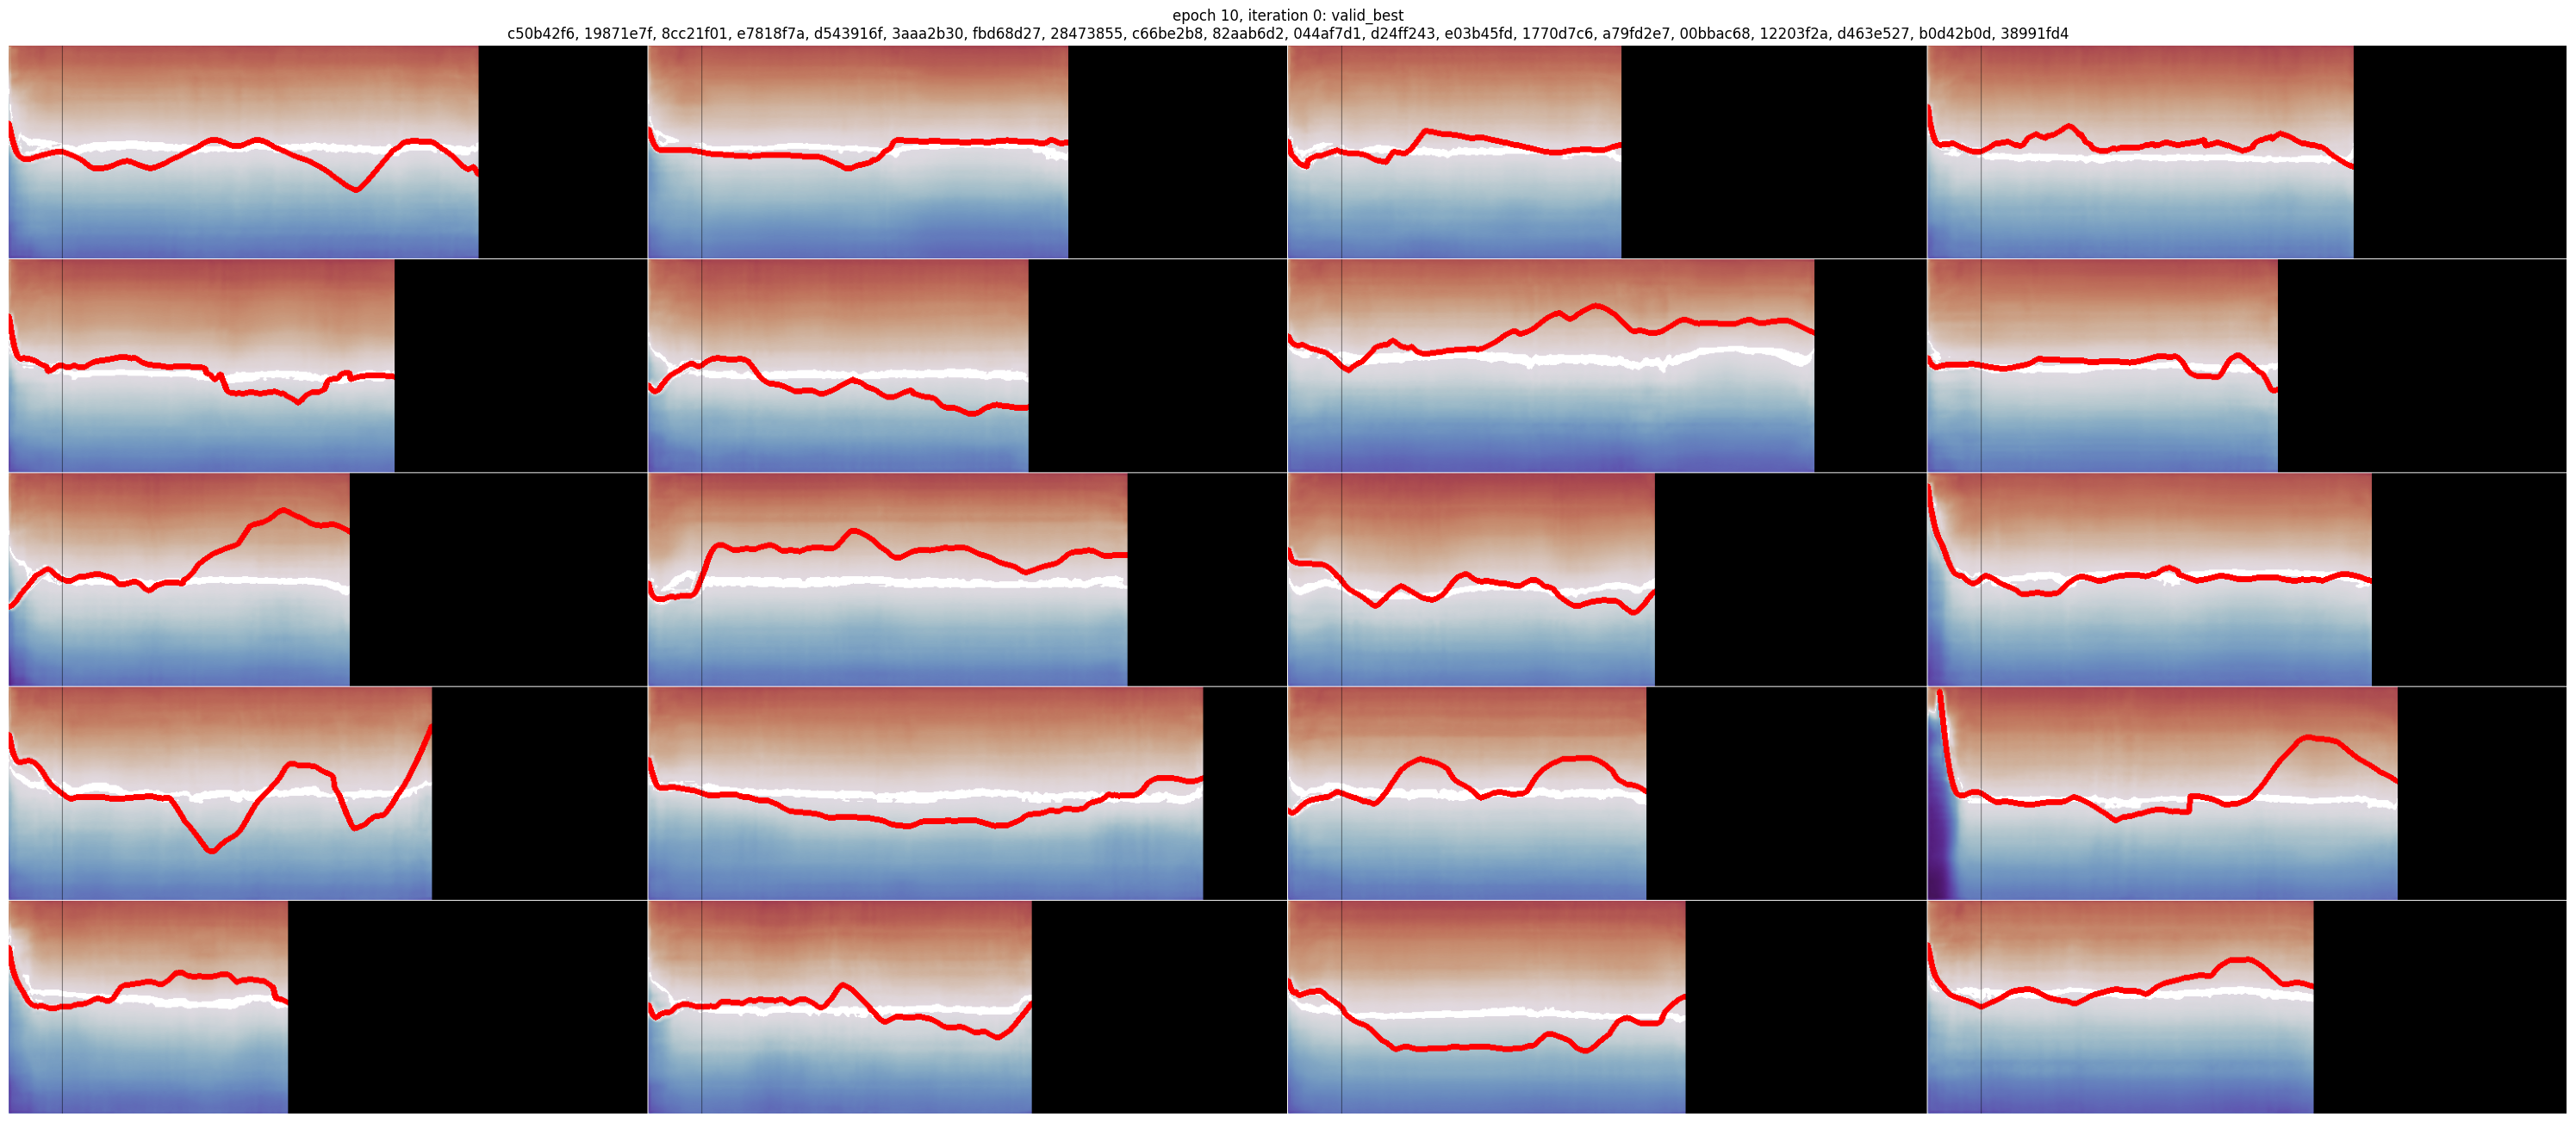

In [36]:
# =========================================================
# Quick visualization with best checkpoint
# white: predicted SDF=0 contour, red: ground truth line
# =========================================================

best_path = OUT_DIR / "best.pth"
if best_path.exists():
    net.load_state_dict(torch.load(best_path, map_location=DEVICE))
    net.eval()

    show_ids = valid_ids[:20]
    batch = make_batch_from_ids(show_ids)
    with torch.no_grad():
        output = net(batch)
        print("sdf_loss:", output["sdf_loss"].item())
        print("rmse_px :", path_rmse_px(output, batch).item())
    show_result_grid(batch, output, epoch=EPOCHS, iteration=0, mode="valid_best", max_items=20)
else:
    print("best.pth not found. Run the training cell first.")


In [17]:
# =========================================================
# Restore real TVT axes for each sample
# =========================================================

def get_tvt_axes_for_sample(sample_id, h_step=H_STEP):
    """
    load_one_sample() と同じ切り出しを行い、
    画像上の縦px/横pxに対応する実TVT配列を返す。
    
    return:
        t_seg_tvt: [T]  縦軸px -> typewell TVT
        h_seg_tvt: [H]  横軸px -> horizontal well true TVT
        t_seg_mask: [T]
        h_seg_mask: [H]
    """
    meta = META_DF[META_DF["sample_id"] == sample_id].iloc[0]
    H_S = h_step // NN_SCALE

    # typewell
    typewell_csv = f"{KAGGLE_DIR}/train/{sample_id}__typewell.csv"
    t = pd.read_csv(typewell_csv)
    t_tvt, t_gr = resample_typewell_by_step(
        t,
        step=meta["t_step"],
        target_step=0.5,
    )

    # horizontal well
    horizontal_csv = f"{KAGGLE_DIR}/train/{sample_id}__horizontal_well.csv"
    h = pd.read_csv(horizontal_csv)

    h_tvt0, h_tvt1, h_gr0, h_gr1 = resample_horizontal_by_step(
        h,
        target_step=H_S,
        offset=0,
    )

    # typewell crop
    last_tvt = h_tvt0[-1]
    last_idx = np.abs(t_tvt - last_tvt).argmin()

    j0, j1, pad_left, pad_right = get_crop_index_and_pad_1d(
        len(t_tvt),
        last_idx + 1,
        history=T_H,
        future=T_F,
    )

    t_seg_mask = np.pad(np.ones((j1 - j0)), (pad_left, pad_right))
    t_seg_tvt = np.pad(t_tvt[j0:j1], (pad_left, pad_right))

    # horizontal known part
    j0, j1, pad_left, pad_right = get_crop_index_and_pad_1d(
        len(h_tvt0),
        len(h_tvt0),
        history=H_H,
        future=0,
    )

    h_seg_mask0 = np.pad(np.ones((j1 - j0)), (pad_left, pad_right))
    h_seg_tvt0 = np.pad(h_tvt0[j0:j1], (pad_left, pad_right))

    # horizontal future part
    j0, j1, pad_left, pad_right = get_crop_index_and_pad_1d(
        len(h_tvt1),
        0,
        history=0,
        future=H_F,
    )

    h_seg_mask1 = np.pad(np.ones((j1 - j0)), (pad_left, pad_right))
    h_seg_tvt1 = np.pad(h_tvt1[j0:j1], (pad_left, pad_right))

    h_seg_mask = np.concatenate([h_seg_mask0, h_seg_mask1])
    h_seg_tvt = np.concatenate([h_seg_tvt0, h_seg_tvt1])

    return {
        "t_seg_tvt": t_seg_tvt.astype(np.float32),
        "h_seg_tvt": h_seg_tvt.astype(np.float32),
        "t_seg_mask": t_seg_mask.astype(np.float32),
        "h_seg_mask": h_seg_mask.astype(np.float32),
    }


def extract_sample_id(batch_id):
    """
    batch["id"] が ('sample_id', offset) の形なので sample_id だけ取り出す
    """
    if isinstance(batch_id, (list, tuple)):
        return batch_id[0]
    return batch_id

In [18]:
# =========================================================
# Convert predicted SDF path from y-pixel to real TVT
# =========================================================

@torch.no_grad()
def prediction_to_tvt_df(batch, output, future_only=False):
    """
    output["sdf"] から pred_y を取り、
    typewell TVT軸に戻して pred_tvt を作る。
    
    true_tvt は horizontal well 側の実TVT。
    valid/train では true_tvt が存在するので比較可能。
    test では future の true_tvt は本来使えない点に注意。
    """
    sdf = output["sdf"].detach().cpu().float().numpy()[:, 0]  # [B,T,H]
    pred_y = np.abs(sdf).argmin(axis=1)                       # [B,H]

    target_y = batch["target"].detach().cpu().numpy().astype(int)  # [B,H]
    h_mask = batch["h_mask"].detach().cpu().numpy()                # [B,H]

    rows = []

    B, H = pred_y.shape

    for b in range(B):
        sample_id = extract_sample_id(batch["id"][b])

        axes = get_tvt_axes_for_sample(sample_id, h_step=H_STEP)
        t_seg_tvt = axes["t_seg_tvt"]
        h_seg_tvt = axes["h_seg_tvt"]
        h_seg_mask = axes["h_seg_mask"]

        py = pred_y[b].clip(0, len(t_seg_tvt) - 1)
        ty = target_y[b].clip(0, len(t_seg_tvt) - 1)

        pred_tvt = t_seg_tvt[py]
        true_tvt = h_seg_tvt

        # target_yをtypewell TVTに戻したもの
        # true_tvtとはほぼ同じだが、最近傍typewell TVTに丸められる
        true_tvt_on_typewell = t_seg_tvt[ty]

        mask = (h_mask[b] > 0.5) & (h_seg_mask > 0.5)

        if future_only:
            mask = mask & (np.arange(H) > H_H)

        for x in range(H):
            if not mask[x]:
                continue

            rows.append({
                "sample_id": sample_id,
                "x_px": x,
                "is_future": bool(x > H_H),
                "pred_y_px": int(py[x]),
                "true_y_px": int(ty[x]),
                "pred_tvt": float(pred_tvt[x]),
                "true_tvt": float(true_tvt[x]),
                "true_tvt_on_typewell": float(true_tvt_on_typewell[x]),
                "err_tvt": float(pred_tvt[x] - true_tvt[x]),
                "abs_err_tvt": float(abs(pred_tvt[x] - true_tvt[x])),
                "err_y_px": float(py[x] - ty[x]),
            })

    df = pd.DataFrame(rows)
    return df

In [20]:
# =========================================================
# Run inference and show TVT-space result
# =========================================================

best_path = OUT_DIR / "best.pth"
state = torch.load(best_path, map_location=DEVICE)
net.load_state_dict(state)
net.eval()

show_ids = valid_ids[:8]

batch = make_batch_from_ids(show_ids)

with torch.no_grad():
    output = net(batch)

tvt_df = prediction_to_tvt_df(
    batch,
    output,
    future_only=False,
)

display(tvt_df.head())

rmse_tvt_all = np.sqrt(np.mean(tvt_df["err_tvt"].values ** 2))
rmse_tvt_future = np.sqrt(np.mean(tvt_df[tvt_df["is_future"]]["err_tvt"].values ** 2))

print("RMSE TVT all   :", rmse_tvt_all)
print("RMSE TVT future:", rmse_tvt_future)

 7 28473855


,sample_id,x_px,is_future,pred_y_px,true_y_px,pred_tvt,true_tvt,true_tvt_on_typewell,err_tvt,abs_err_tvt,err_y_px
0,c50b42f6,0,False,88,93,10947.120117,10949.809570,10949.620117,-2.689453,2.689453,-5.0
1,c50b42f6,1,False,94,99,10950.120117,10952.540039,10952.620117,-2.419922,2.419922,-5.0
2,c50b42f6,2,False,105,104,10955.620117,10955.036133,10955.120117,0.583984,0.583984,1.0
3,c50b42f6,3,False,108,108,10957.120117,10957.291016,10957.120117,-0.170898,0.170898,0.0
4,c50b42f6,4,False,114,112,10960.120117,10959.333984,10959.120117,0.786133,0.786133,2.0


RMSE TVT all   : 9.49137123058709
RMSE TVT future: 10.04967227614132


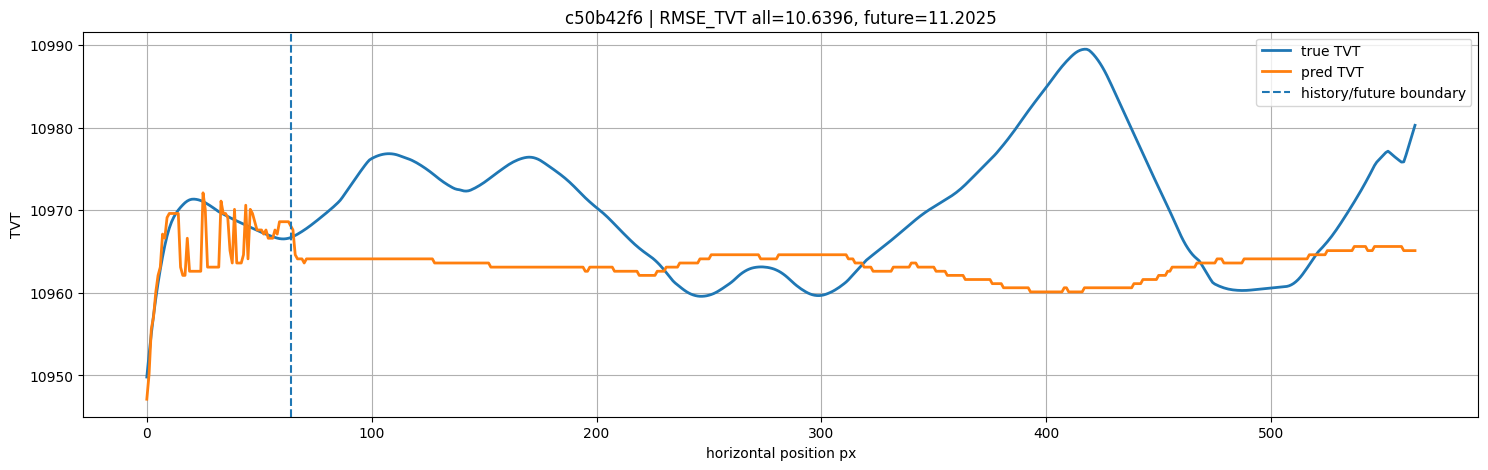

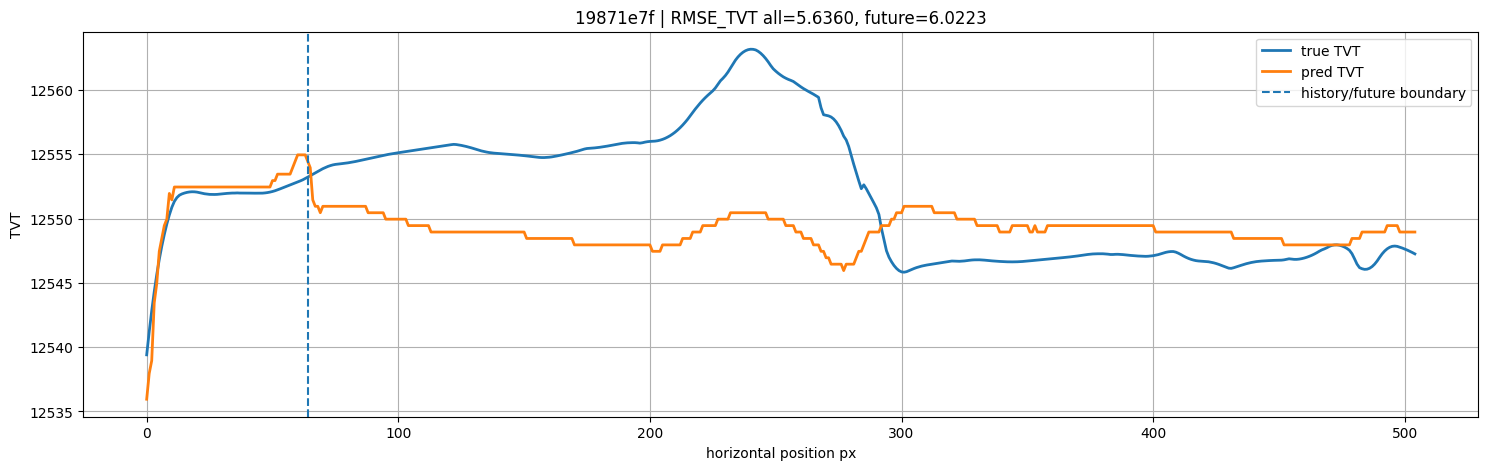

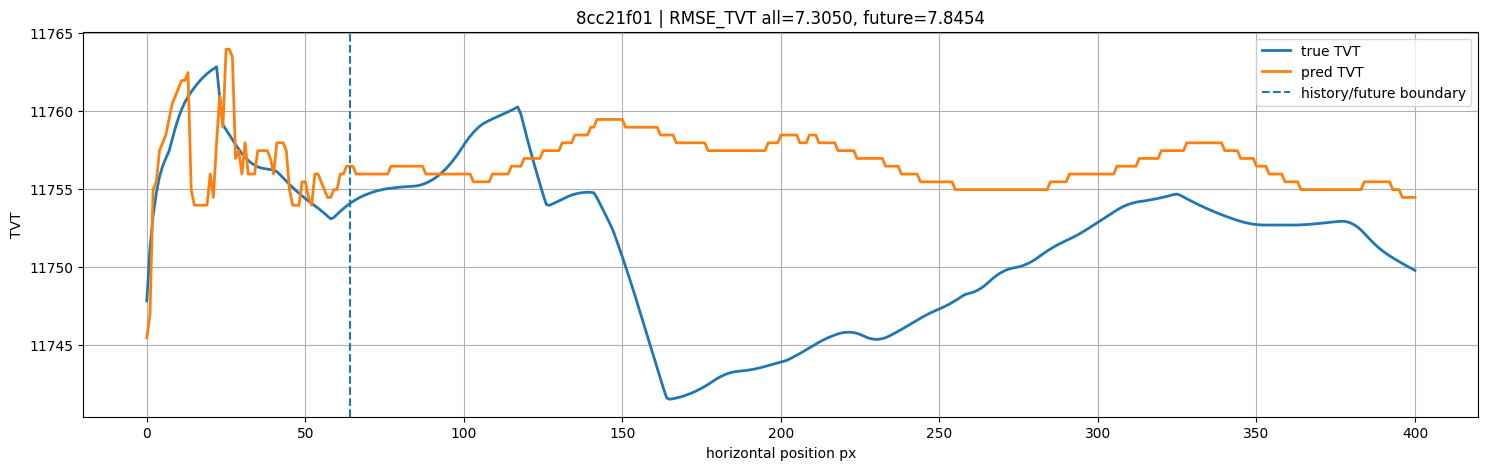

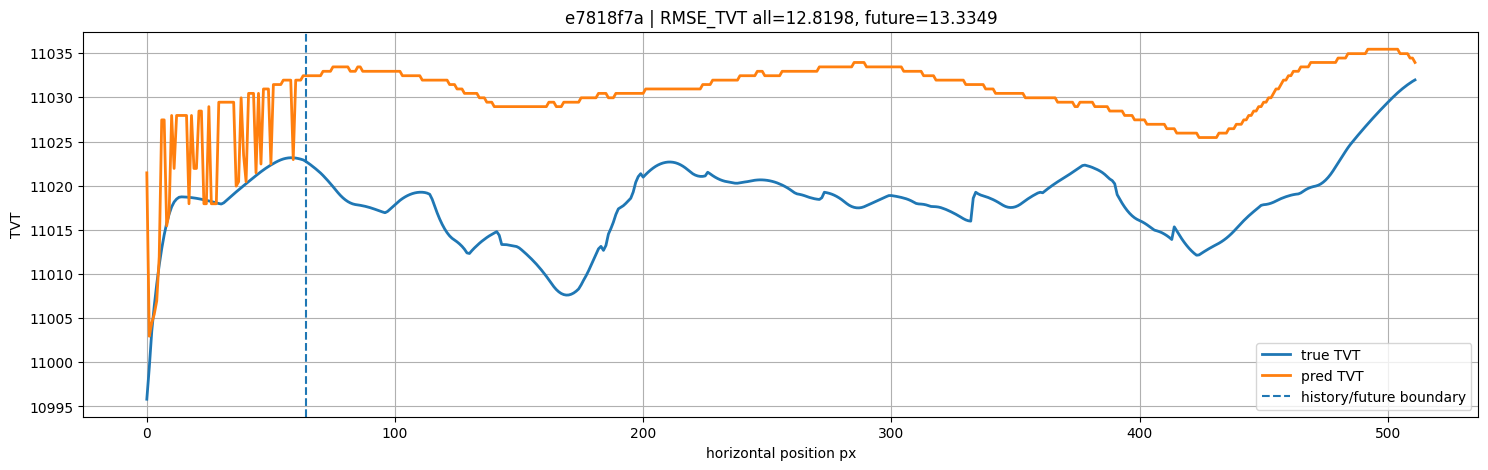

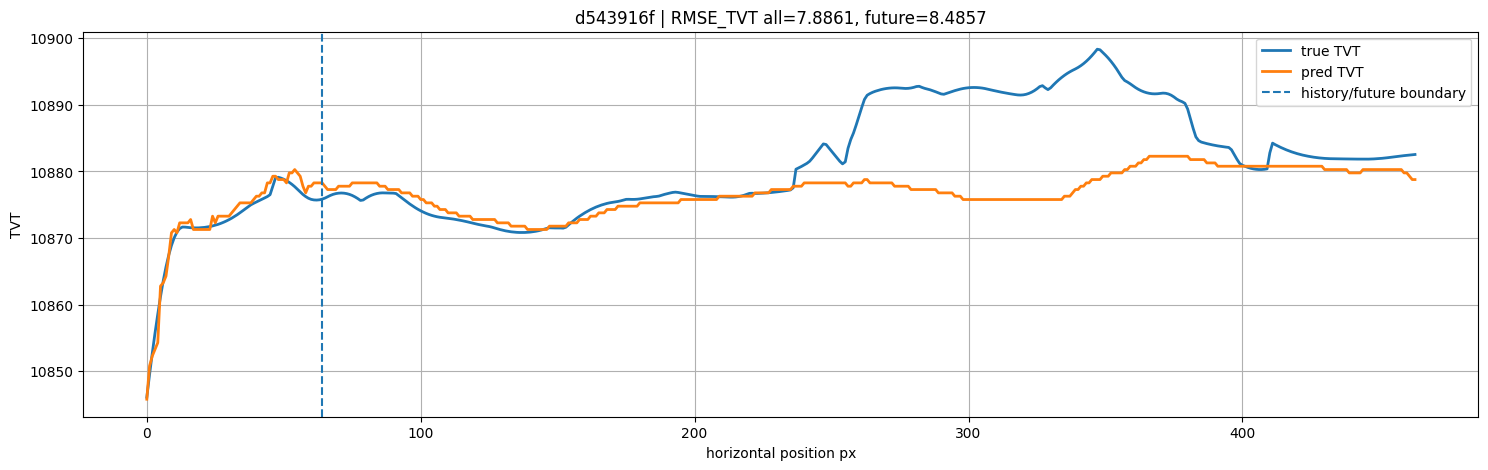

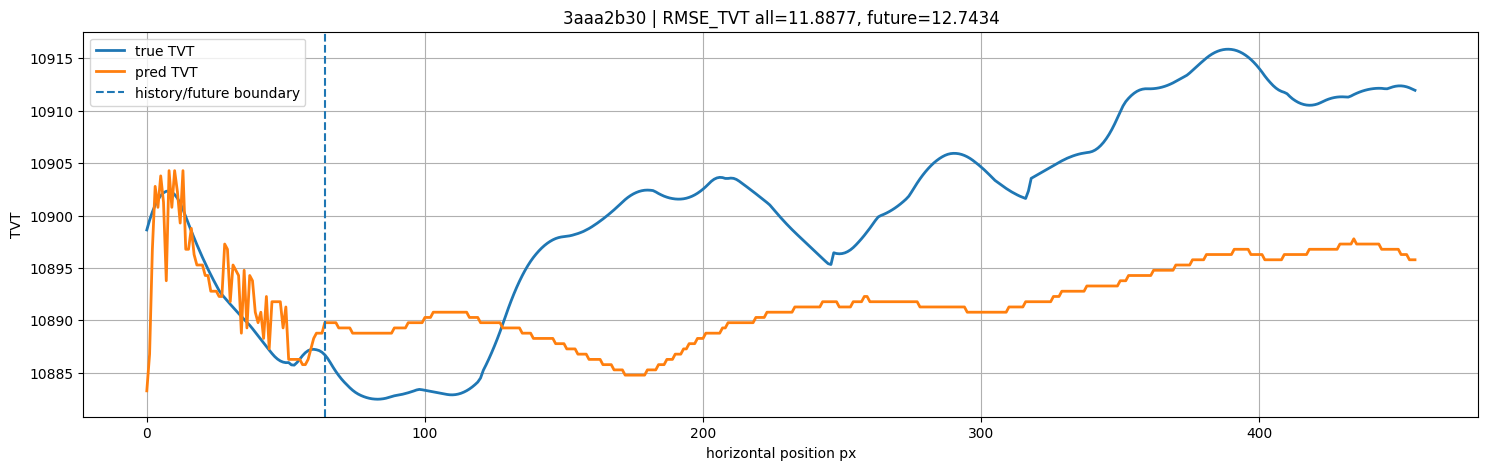

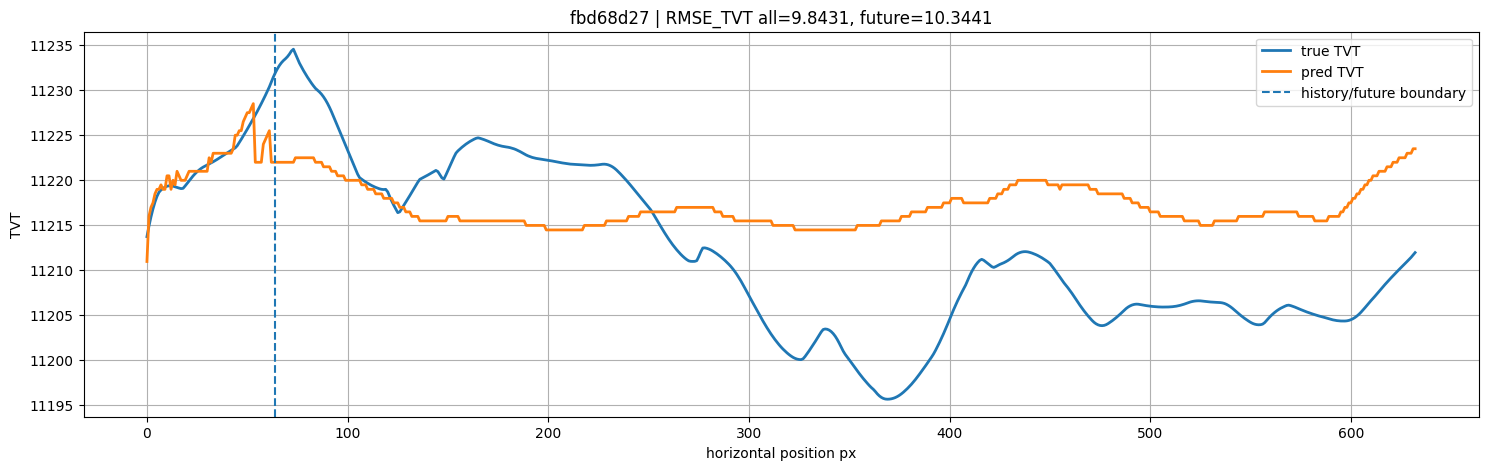

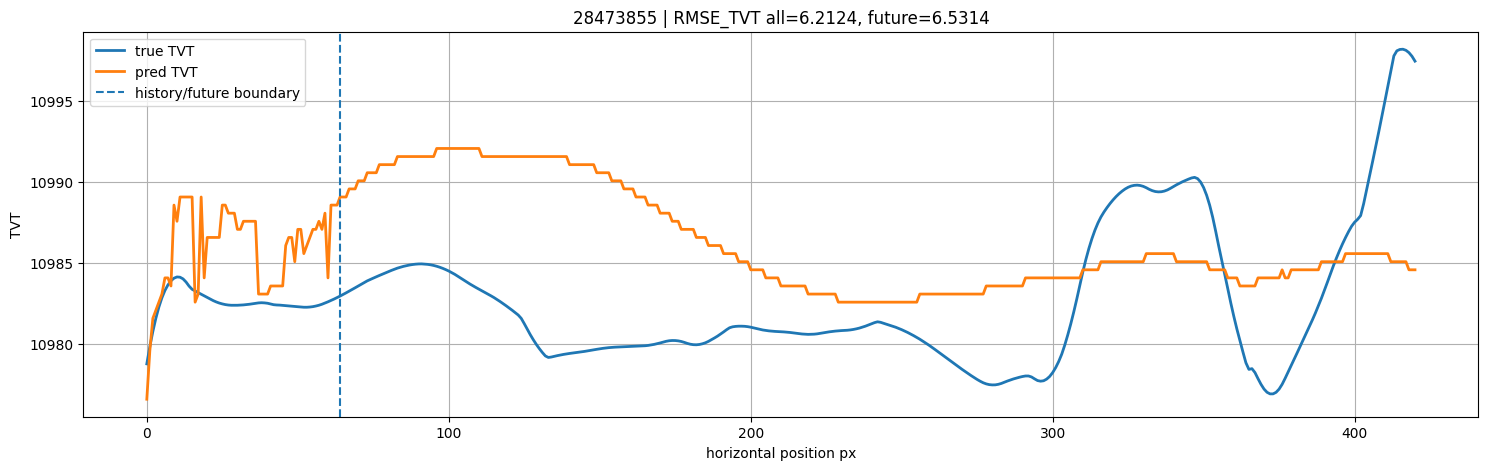

In [21]:
# =========================================================
# Plot predicted TVT vs true TVT
# =========================================================

def plot_tvt_prediction(tvt_df, sample_id):
    d = tvt_df[tvt_df["sample_id"] == sample_id].copy()
    if len(d) == 0:
        print("no rows:", sample_id)
        return

    rmse_all = np.sqrt(np.mean(d["err_tvt"].values ** 2))

    future = d[d["is_future"]]
    if len(future):
        rmse_future = np.sqrt(np.mean(future["err_tvt"].values ** 2))
    else:
        rmse_future = np.nan

    fig, ax = plt.subplots(1, 1, figsize=(18, 5))

    ax.plot(
        d["x_px"],
        d["true_tvt"],
        label="true TVT",
        linewidth=2,
    )

    ax.plot(
        d["x_px"],
        d["pred_tvt"],
        label="pred TVT",
        linewidth=2,
    )

    ax.axvline(H_H, linestyle="--", label="history/future boundary")

    ax.set_title(
        f"{sample_id} | RMSE_TVT all={rmse_all:.4f}, future={rmse_future:.4f}"
    )
    ax.set_xlabel("horizontal position px")
    ax.set_ylabel("TVT")
    ax.legend()
    ax.grid(True)
    plt.show()


for sid in show_ids:
    plot_tvt_prediction(tvt_df, sid)

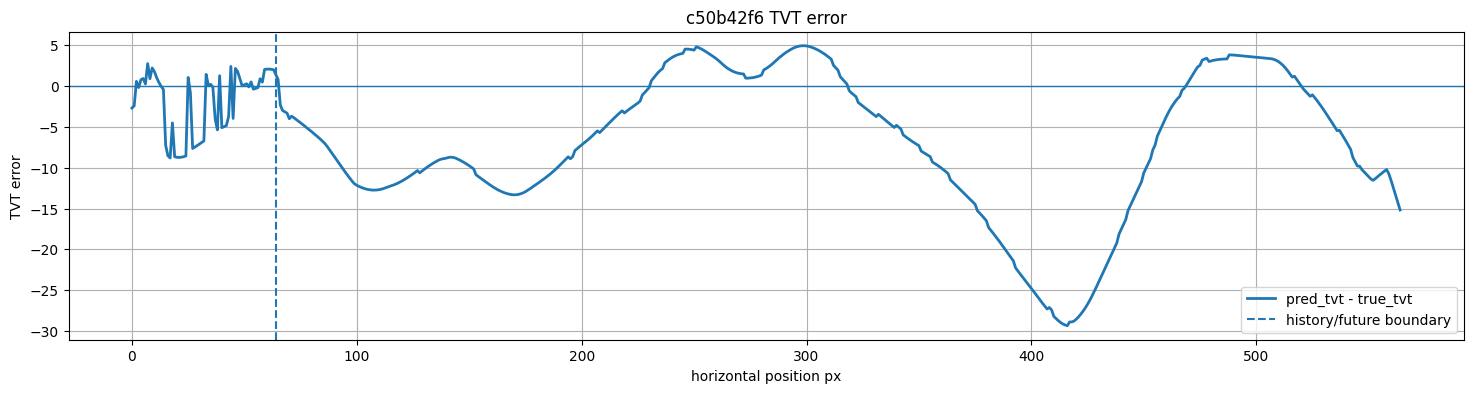

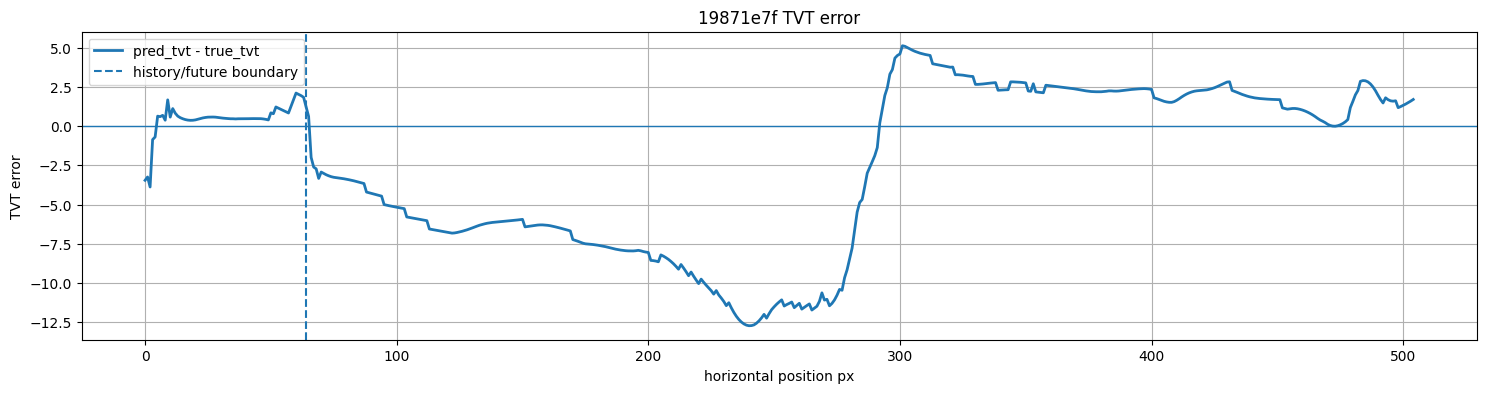

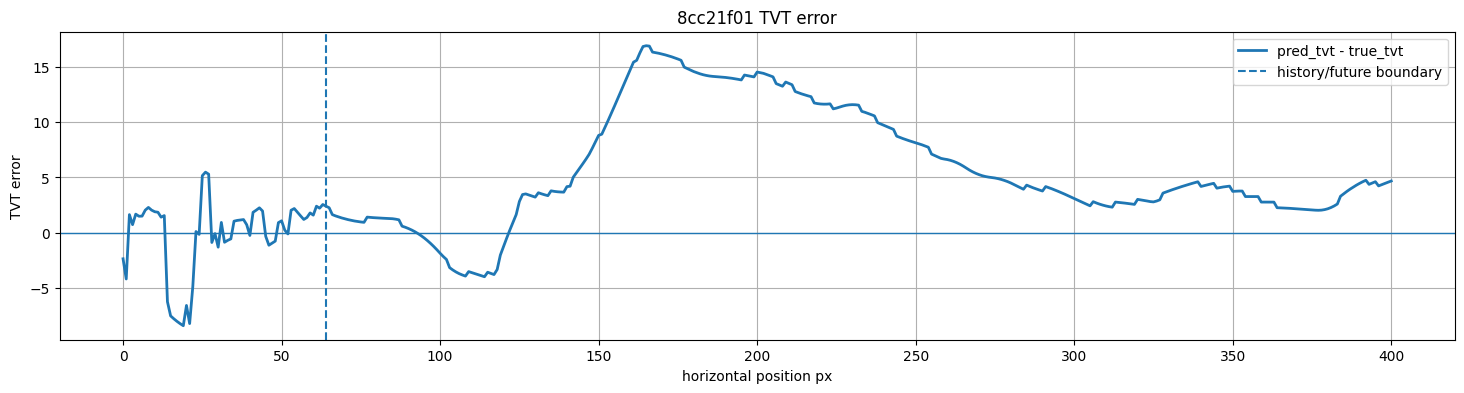

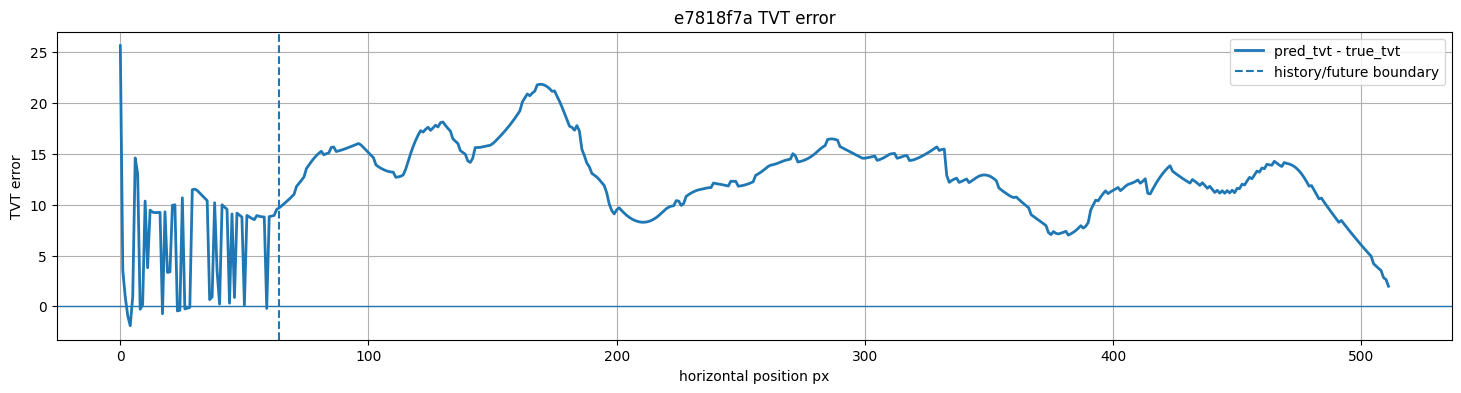

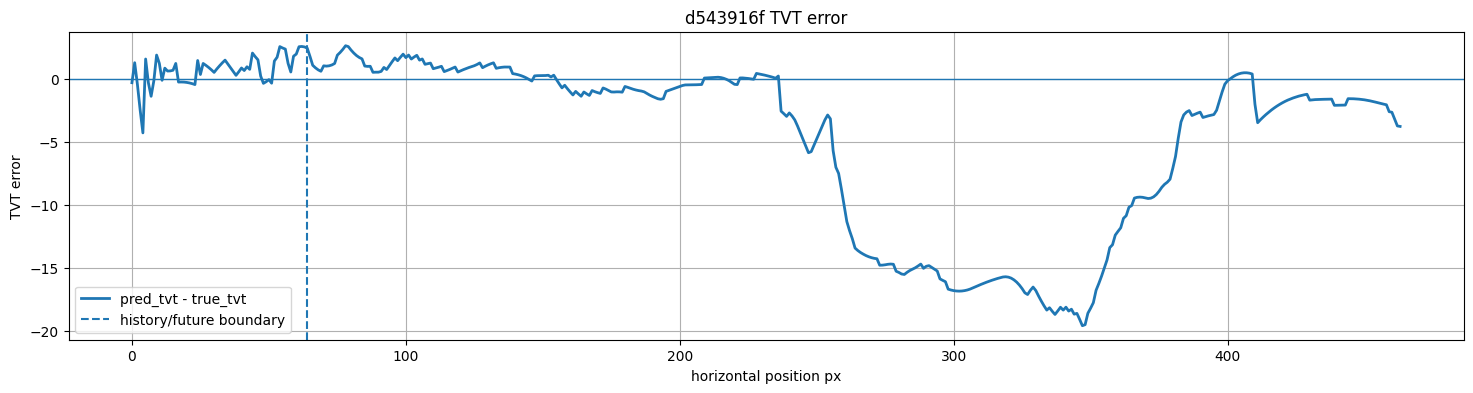

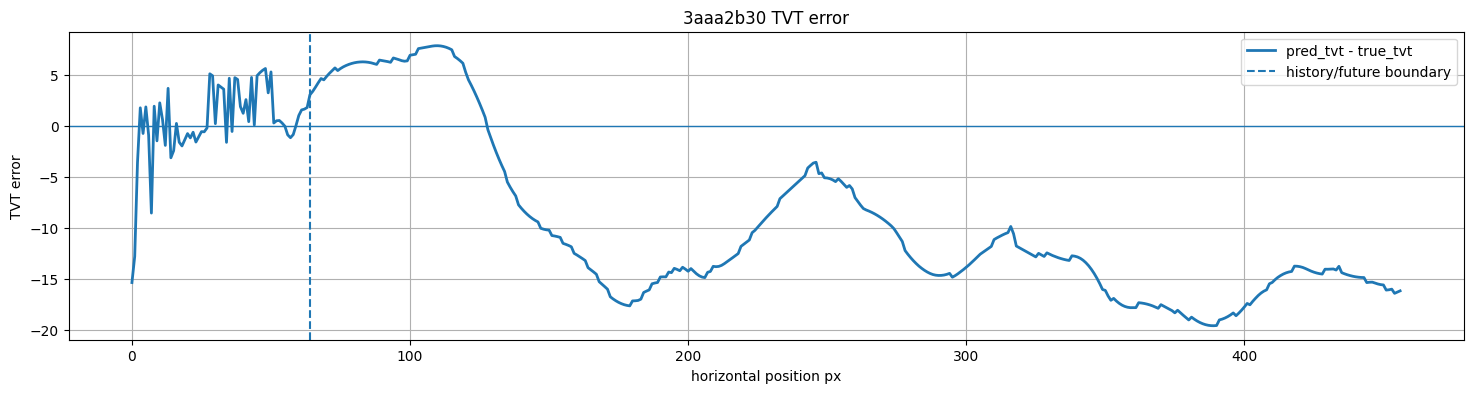

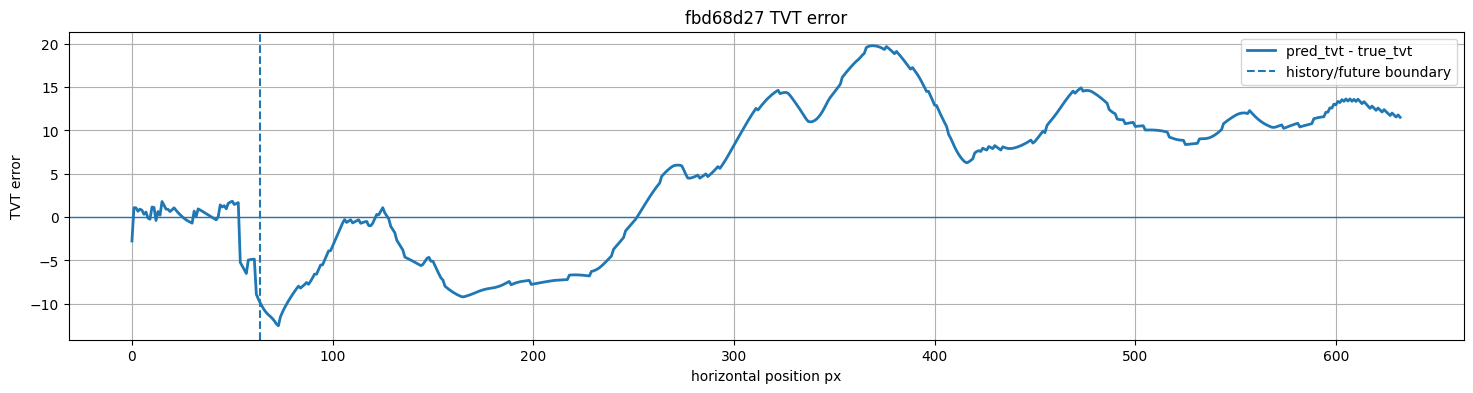

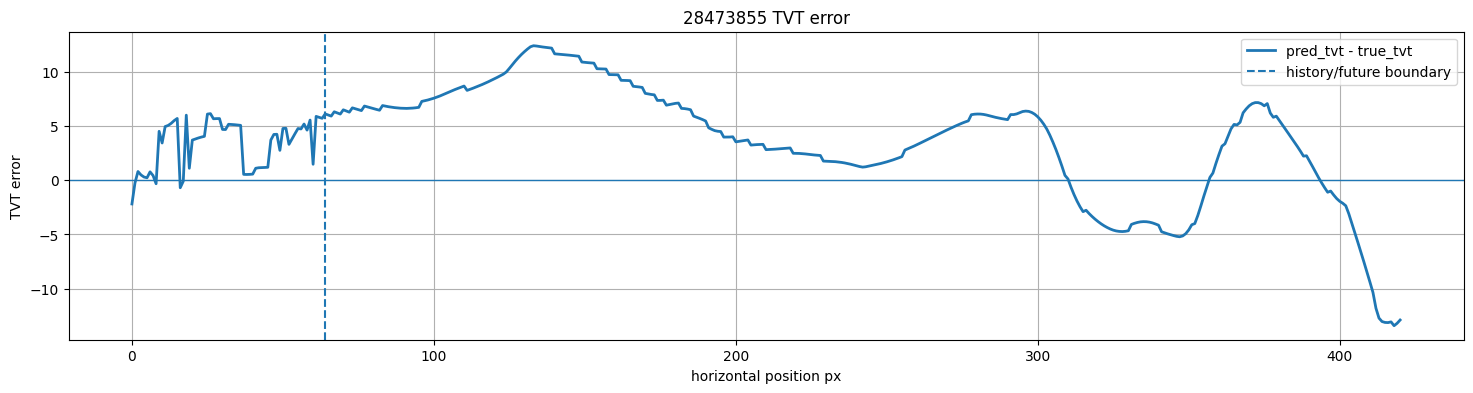

In [22]:
# =========================================================
# Plot TVT error
# =========================================================

def plot_tvt_error(tvt_df, sample_id):
    d = tvt_df[tvt_df["sample_id"] == sample_id].copy()
    if len(d) == 0:
        print("no rows:", sample_id)
        return

    fig, ax = plt.subplots(1, 1, figsize=(18, 4))

    ax.plot(
        d["x_px"],
        d["err_tvt"],
        label="pred_tvt - true_tvt",
        linewidth=2,
    )

    ax.axhline(0, linewidth=1)
    ax.axvline(H_H, linestyle="--", label="history/future boundary")

    ax.set_title(f"{sample_id} TVT error")
    ax.set_xlabel("horizontal position px")
    ax.set_ylabel("TVT error")
    ax.legend()
    ax.grid(True)
    plt.show()


for sid in show_ids:
    plot_tvt_error(tvt_df, sid)

 7 e32da4ec


,sample_id,x_px,is_future,pred_y_px,true_y_px,pred_tvt,true_tvt,true_tvt_on_typewell,err_tvt,abs_err_tvt,err_y_px
0,3ef98781,0,False,101,125,11950.950195,11963.068359,11962.950195,-12.118164,12.118164,-24.0
1,3ef98781,1,False,132,128,11966.450195,11964.672852,11964.450195,1.777344,1.777344,4.0
2,3ef98781,2,False,122,131,11961.450195,11966.014648,11965.950195,-4.564453,4.564453,-9.0
3,3ef98781,3,False,115,133,11957.950195,11967.116211,11966.950195,-9.166016,9.166016,-18.0
4,3ef98781,4,False,121,135,11960.950195,11968.010742,11967.950195,-7.060547,7.060547,-14.0


Train RMSE TVT all   : 20.35483855036834
Train RMSE TVT future: 21.800511775549356


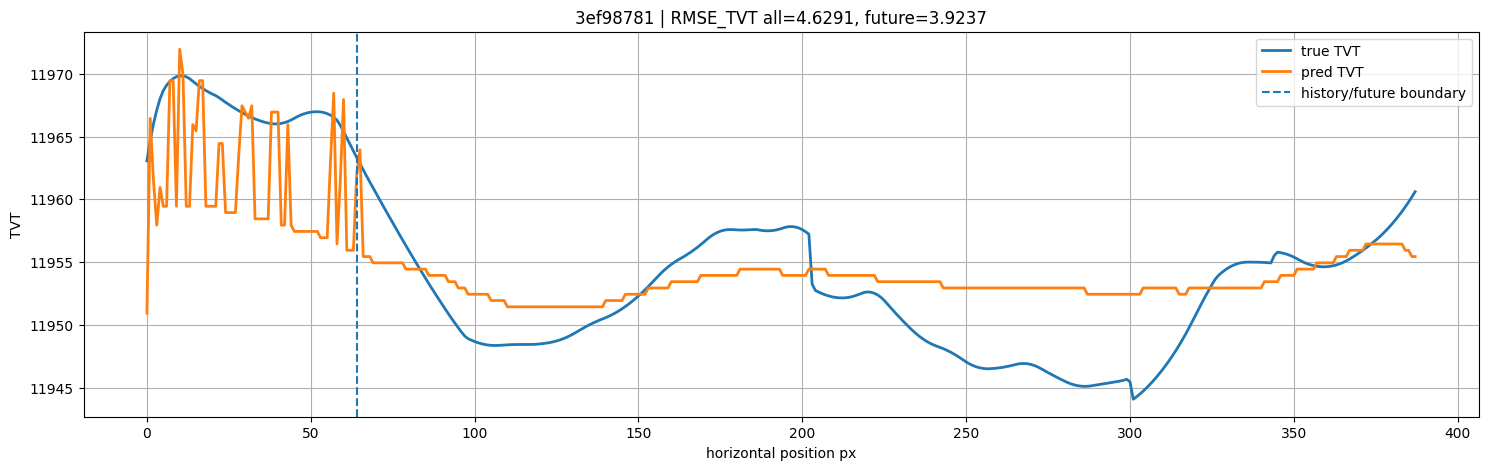

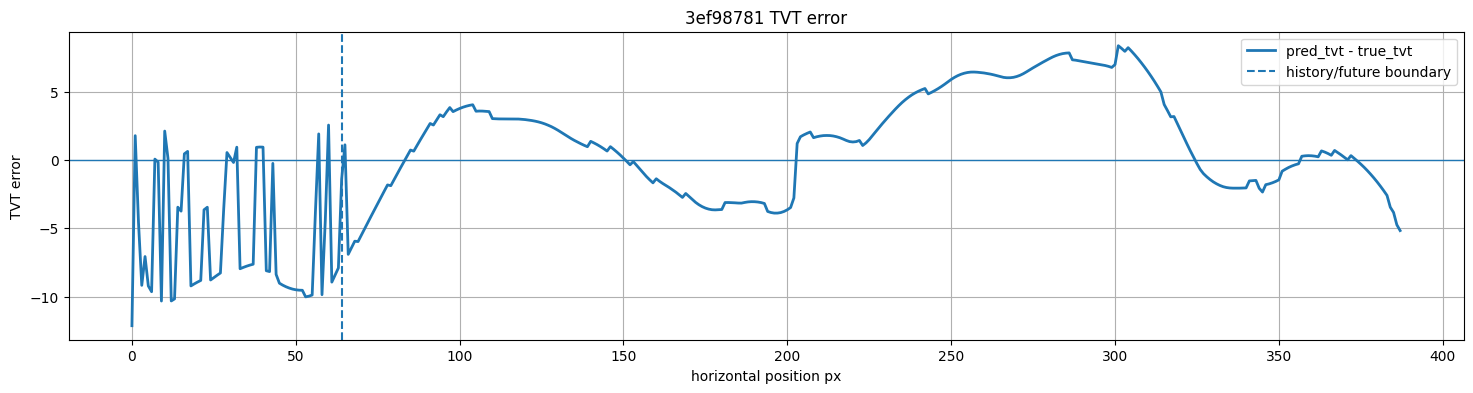

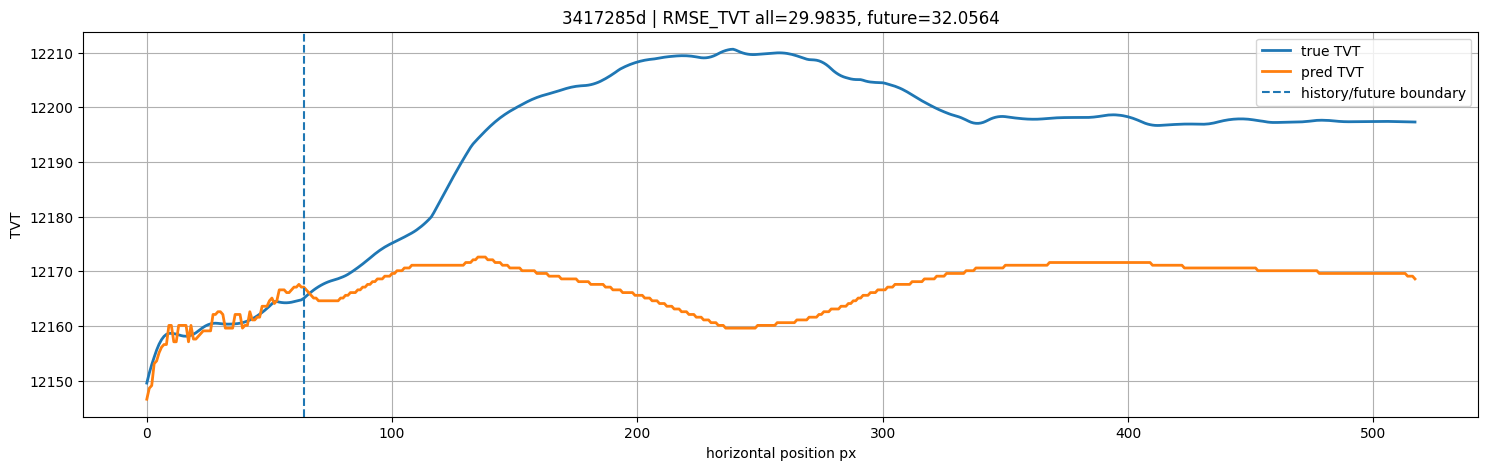

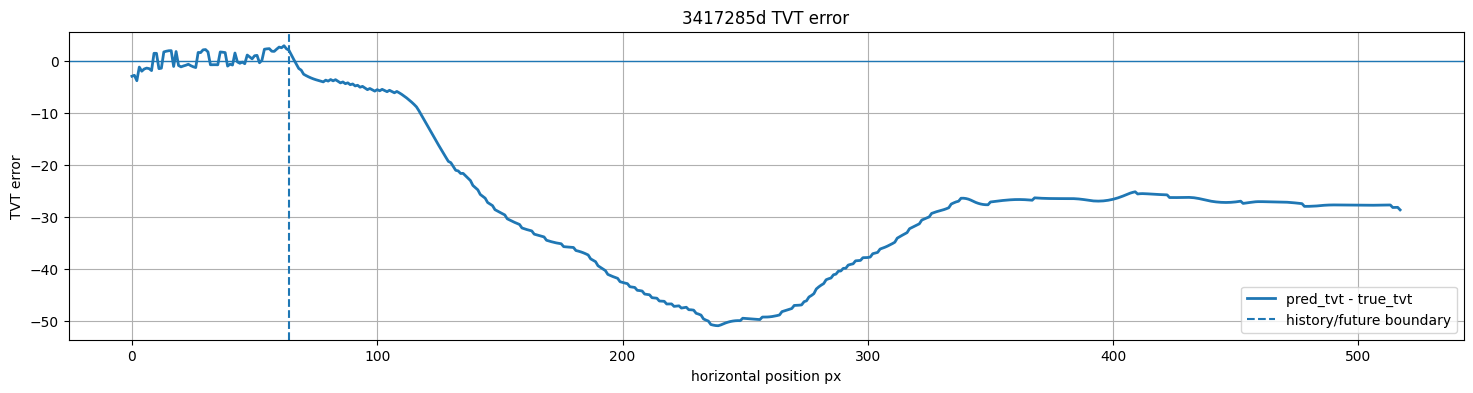

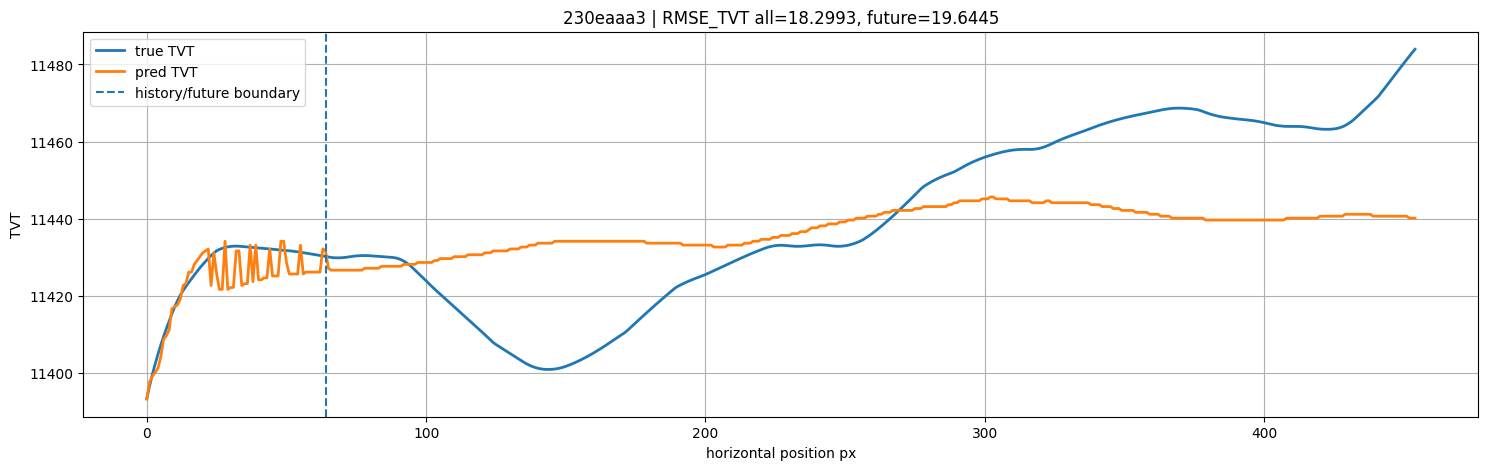

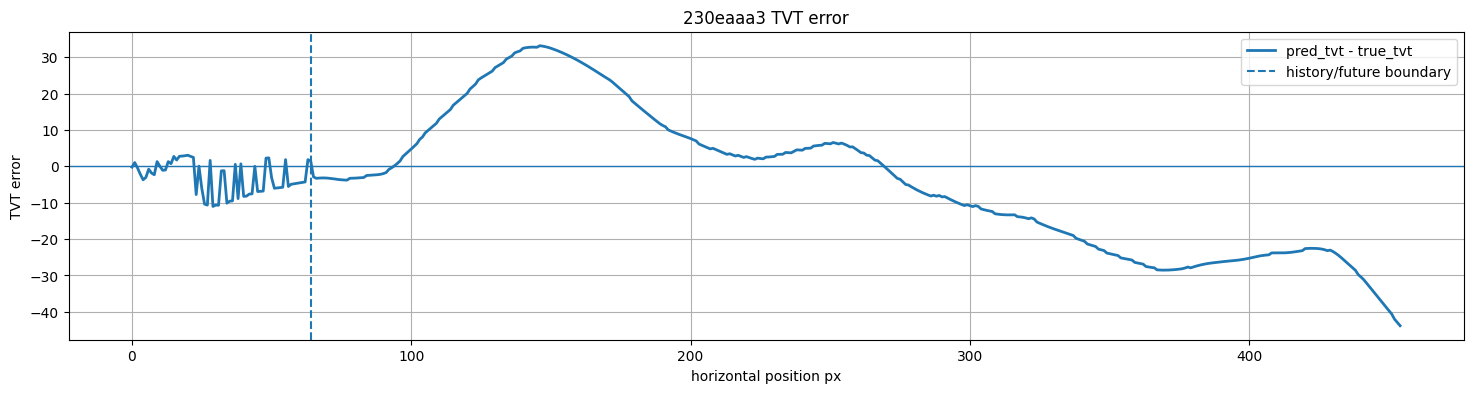

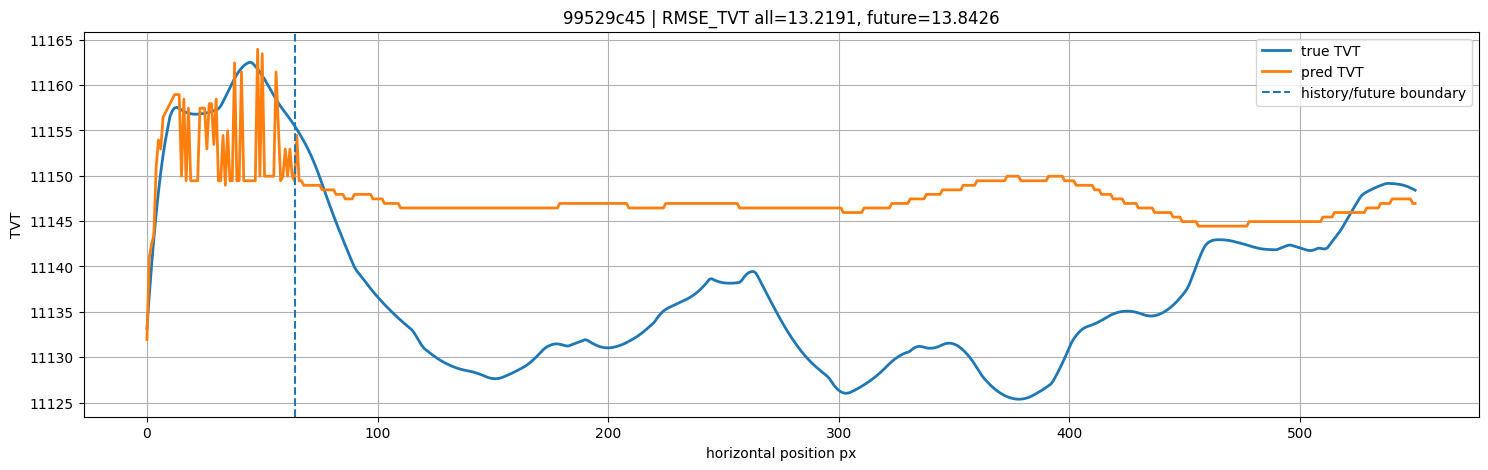

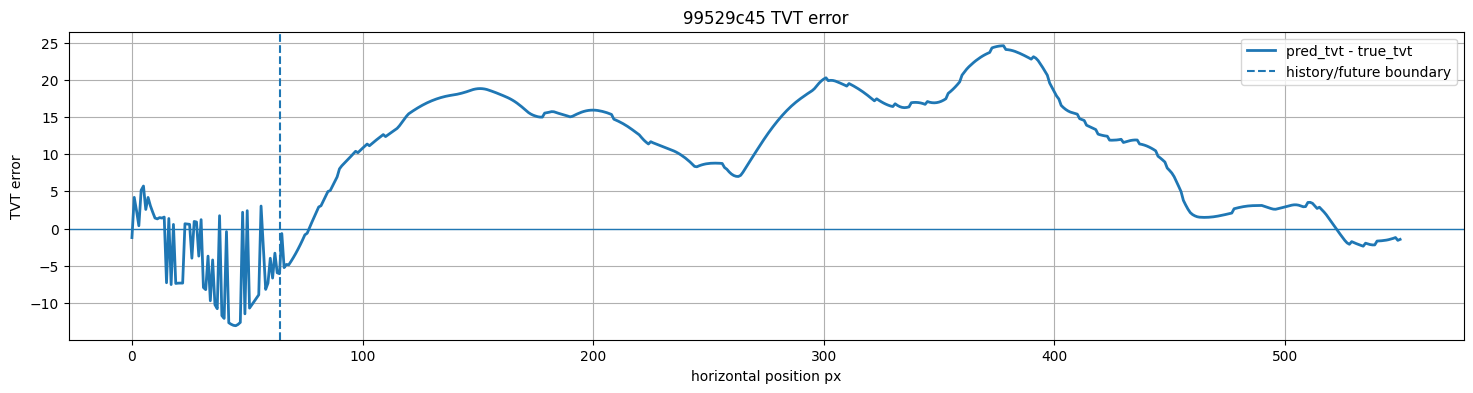

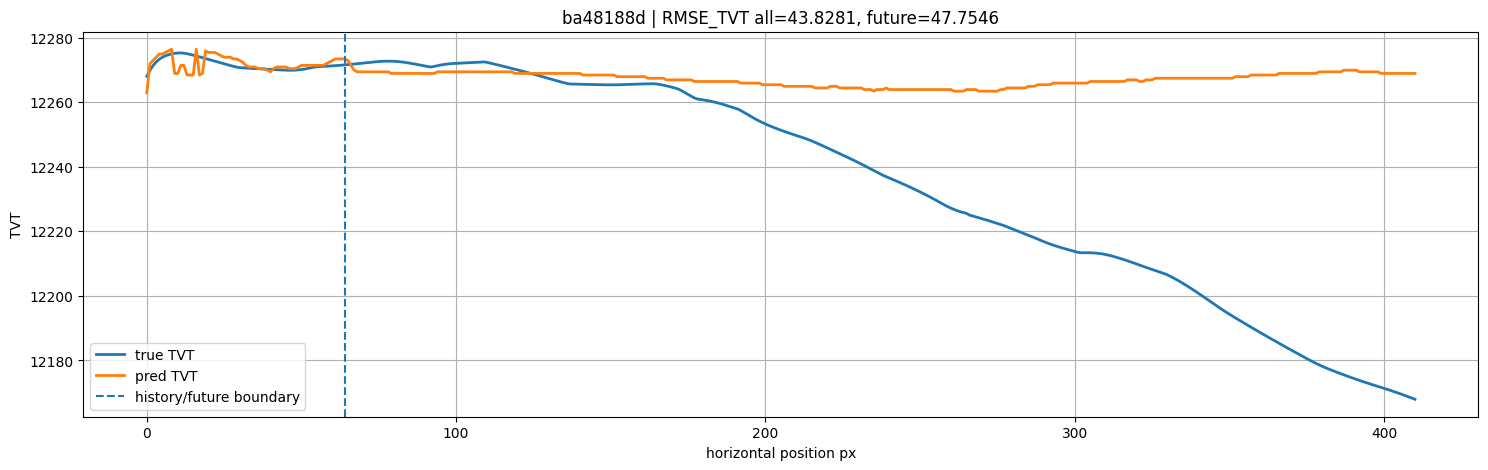

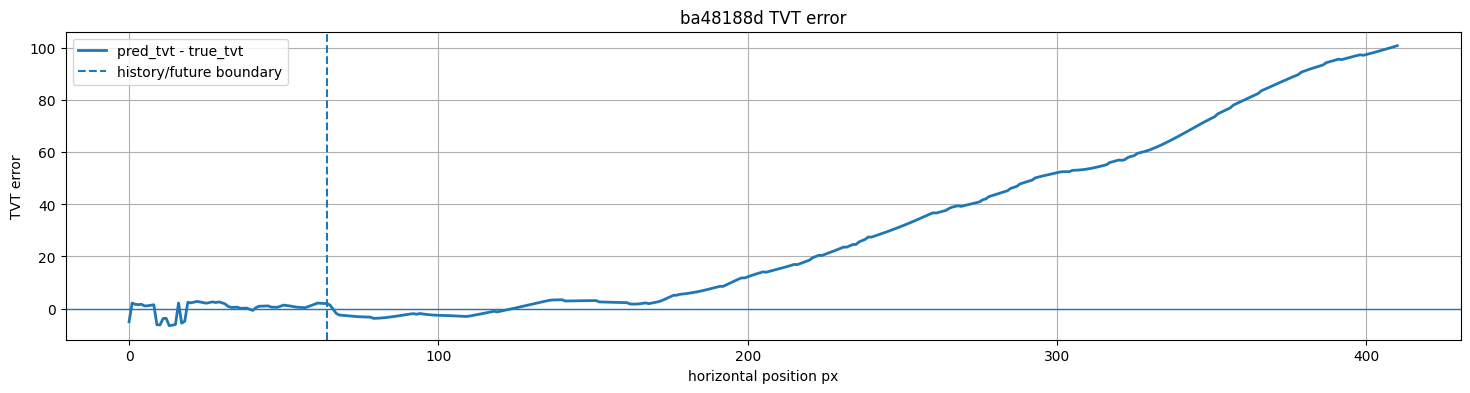

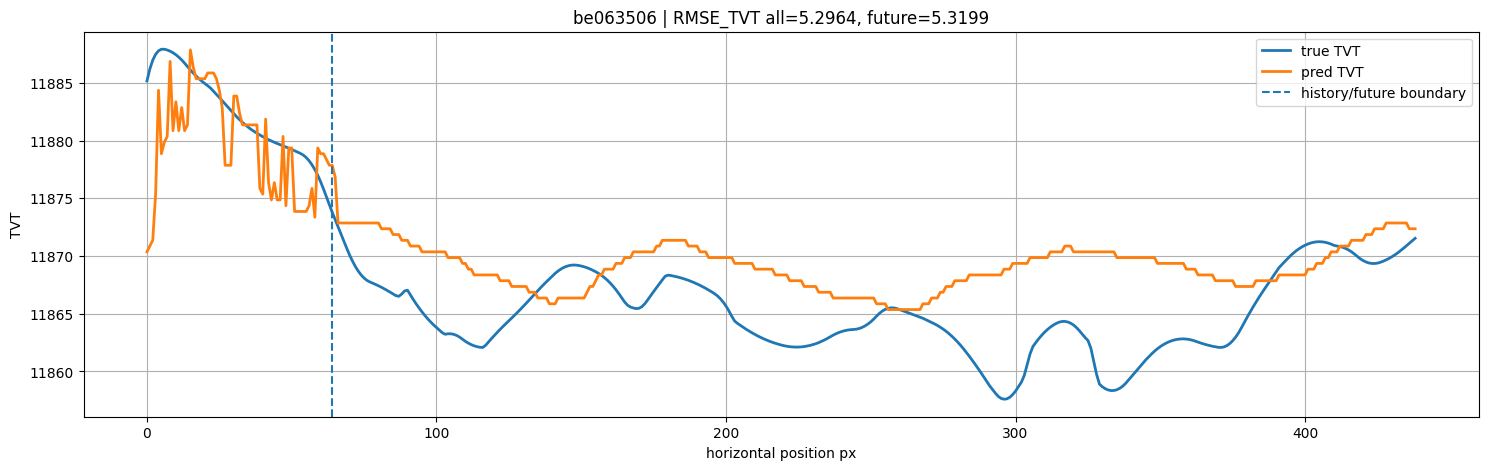

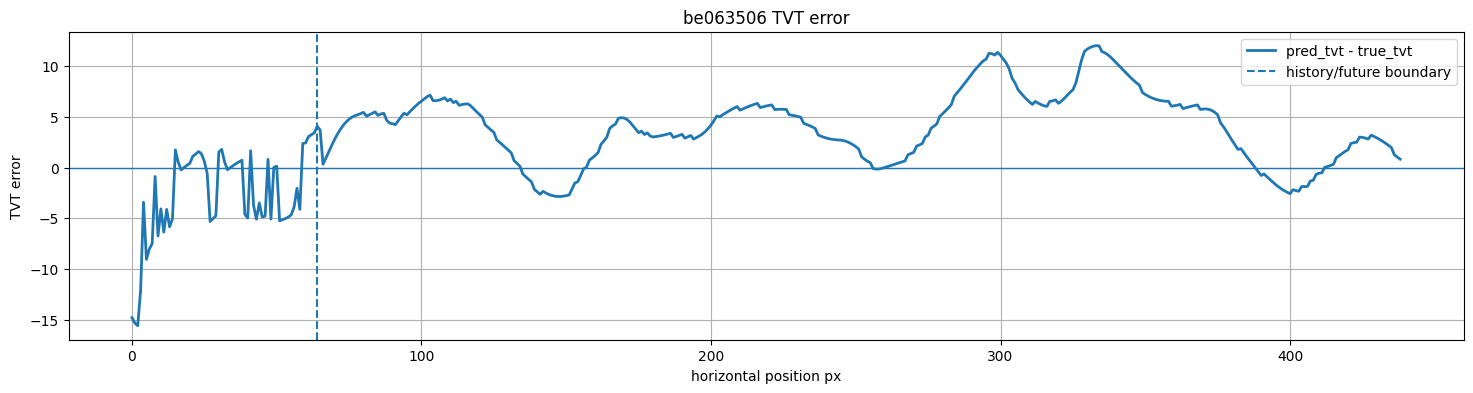

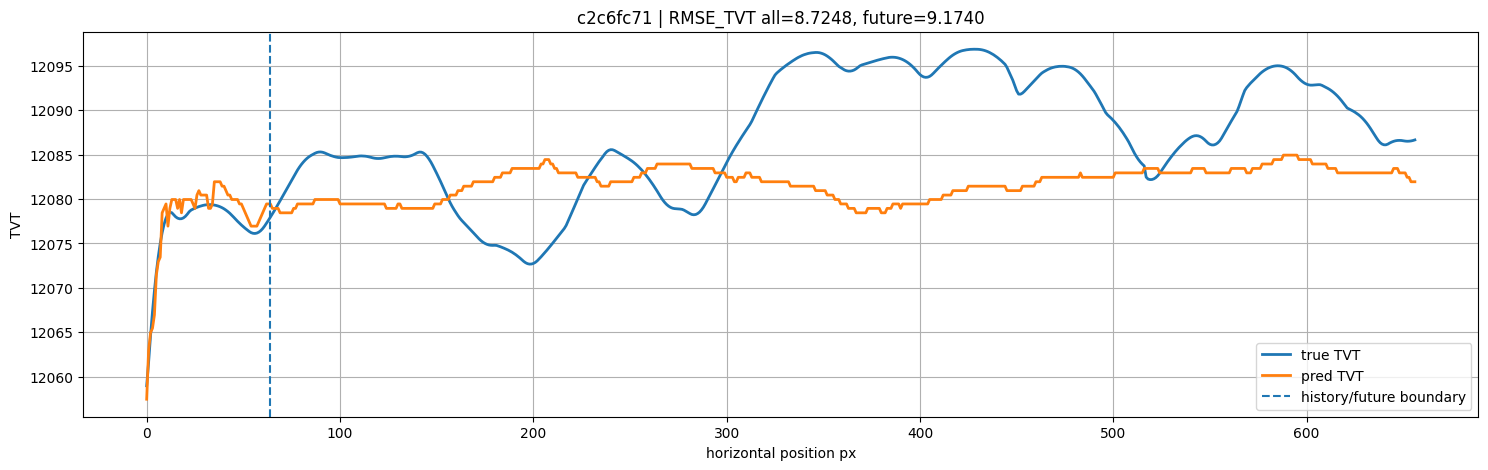

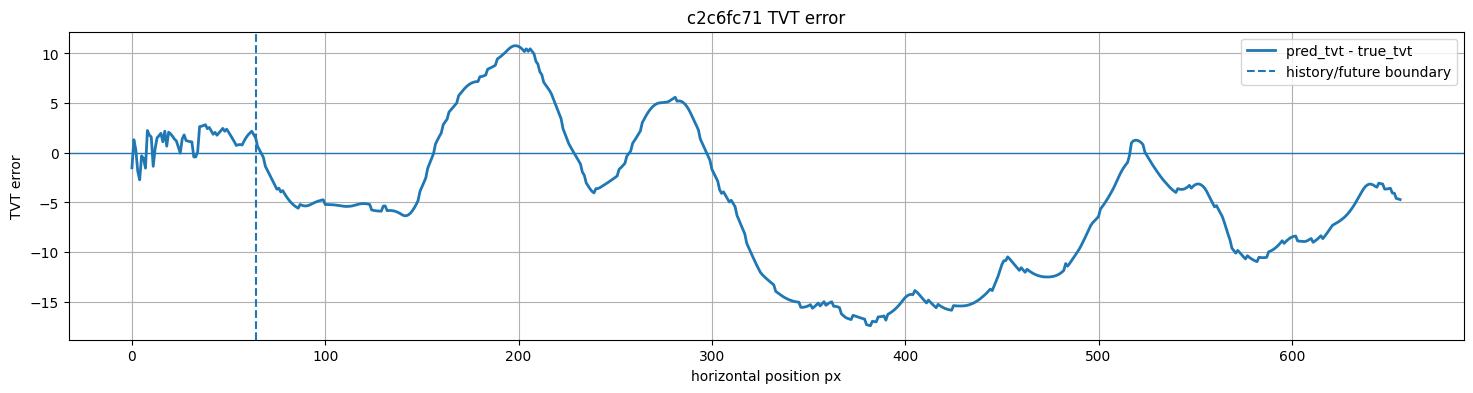

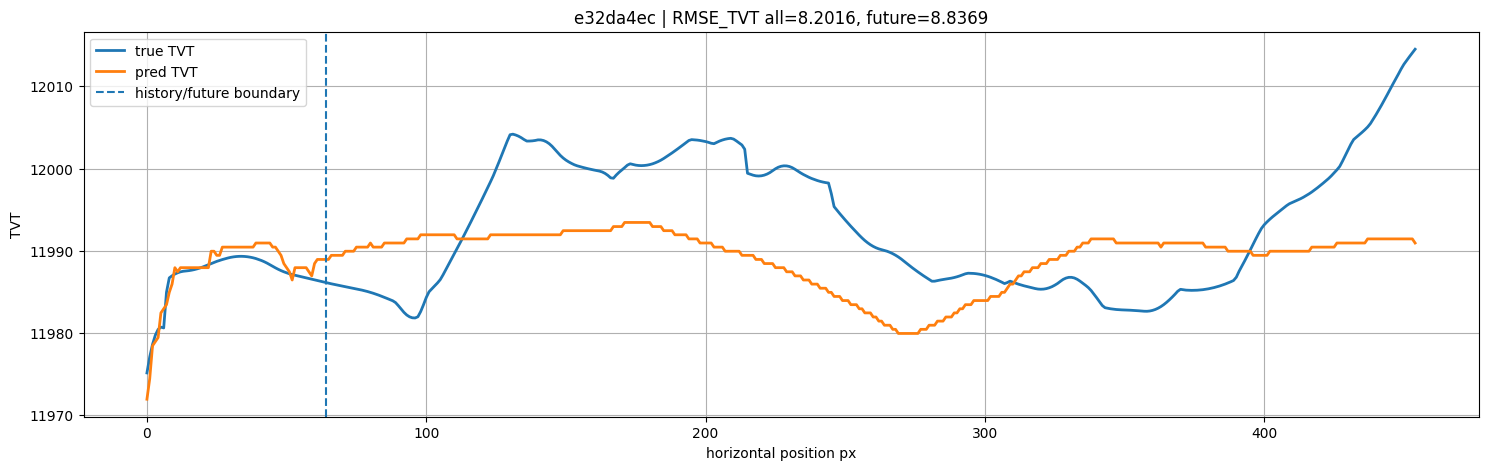

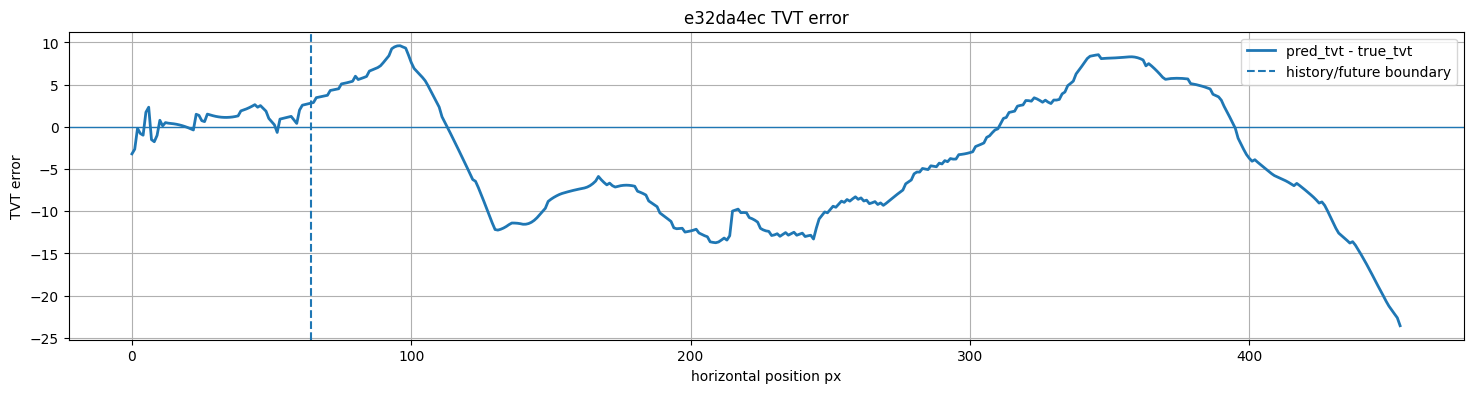

In [24]:
# =========================================================
# Show train prediction in real TVT
# =========================================================

show_ids = random.sample(train_ids, min(8, len(train_ids)))

batch = make_batch_from_ids(show_ids)

with torch.no_grad():
    output = net(batch)

train_tvt_df = prediction_to_tvt_df(
    batch,
    output,
    future_only=False,
)

display(train_tvt_df.head())

rmse_tvt_all = np.sqrt(np.mean(train_tvt_df["err_tvt"].values ** 2))

future_df = train_tvt_df[train_tvt_df["is_future"]]
rmse_tvt_future = np.sqrt(np.mean(future_df["err_tvt"].values ** 2))

print("Train RMSE TVT all   :", rmse_tvt_all)
print("Train RMSE TVT future:", rmse_tvt_future)

for sid in show_ids:
    plot_tvt_prediction(train_tvt_df, sid)
    plot_tvt_error(train_tvt_df, sid)

In [1]:
# =========================================================
# Actual valid RMSE in original horizontal_well rows
# =========================================================

def safe_load_state(path, map_location=DEVICE):
    try:
        return torch.load(str(path), map_location=map_location, weights_only=True)
    except TypeError:
        return torch.load(str(path), map_location=map_location)


def get_t_seg_tvt_for_sample(sample_id, h_step=H_STEP):
    """
    CNN画像の縦軸 y_px -> 実TVT を復元する。
    load_one_sample() と同じ crop を再現する。
    """
    meta = META_DF[META_DF["sample_id"] == sample_id].iloc[0]
    H_S = h_step // NN_SCALE

    typewell_csv = f"{KAGGLE_DIR}/train/{sample_id}__typewell.csv"
    t = pd.read_csv(typewell_csv)
    t_tvt, t_gr = resample_typewell_by_step(
        t,
        step=meta["t_step"],
        target_step=0.5,
    )

    horizontal_csv = f"{KAGGLE_DIR}/train/{sample_id}__horizontal_well.csv"
    h = pd.read_csv(horizontal_csv)

    h_tvt0, h_tvt1, h_gr0, h_gr1 = resample_horizontal_by_step(
        h,
        target_step=H_S,
        offset=0,
    )

    last_tvt = h_tvt0[-1]
    last_idx = np.abs(t_tvt - last_tvt).argmin()

    j0, j1, pad_left, pad_right = get_crop_index_and_pad_1d(
        len(t_tvt),
        last_idx + 1,
        history=T_H,
        future=T_F,
    )

    t_seg_tvt = np.pad(t_tvt[j0:j1], (pad_left, pad_right))

    return t_seg_tvt.astype(np.float32)


def make_future_group_x_for_sample(sample_id, h_step=H_STEP):
    """
    resample_horizontal_by_step() と同じ future 側の group 化を再現し、
    CNN横軸の future x_px が元CSVのどの位置に対応するかを作る。
    """
    H_S = h_step // NN_SCALE

    horizontal_csv = f"{KAGGLE_DIR}/train/{sample_id}__horizontal_well.csv"
    h = pd.read_csv(horizontal_csv)

    tvt_input_notna = h["TVT_input"].notna().values
    h_ps = int(np.flatnonzero(tvt_input_notna)[-1])

    # 元CSV上のfuture行
    future_start = h_ps + 1
    future_df = h.iloc[future_start:].copy()

    if len(future_df) == 0:
        return None

    # MD列があればMDで補間、なければ行番号で補間
    if "MD" in h.columns:
        x_all = h["MD"].values.astype(np.float32)
    else:
        x_all = np.arange(len(h), dtype=np.float32)

    future_x = x_all[future_start:].astype(np.float32)

    # resample_horizontal_by_step() の after 側と同じ pad/truncate
    group_x = future_x.copy()

    pad_after = (-len(group_x)) % H_S

    if pad_after < H_S // 2:
        if pad_after > 0:
            group_x = np.pad(group_x, (0, pad_after), mode="edge")
    else:
        cut = H_S - pad_after
        if cut > 0:
            group_x = group_x[:-cut]

    if len(group_x) < H_S:
        return None

    group_x = group_x.reshape(len(group_x) // H_S, H_S).mean(axis=1)

    # CNNはfuture側を最大H_F列だけ持つ
    group_x = group_x[:H_F]

    return {
        "h": h,
        "future_start": future_start,
        "future_x": future_x,
        "future_true_tvt": h["TVT"].values[future_start:].astype(np.float32),
        "group_x": group_x.astype(np.float32),
    }


@torch.no_grad()
def calc_valid_actual_rmse(
    net,
    ids,
    batch_size=4,
    use_all_future_rows=True,
):
    """
    valid_idsに対して、元horizontal_well.csvのfuture行に戻したTVT RMSEを計算する。

    use_all_future_rows=True:
        元CSVのfuture全行を評価する。
        CNNの範囲外の末尾がある場合は、最後の予測値で外挿される。

    use_all_future_rows=False:
        CNNのresample group範囲内だけ評価する。
    """
    net.eval()

    rows = []

    for i in tqdm(range(0, len(ids), batch_size), desc="valid actual rmse"):
        batch_ids = ids[i:i + batch_size]

        batch = make_batch_from_ids(batch_ids)

        with torch.no_grad():
            output = net(batch)

        sdf = output["sdf"].detach().cpu().float().numpy()[:, 0]  # [B,T,H]
        pred_y = np.abs(sdf).argmin(axis=1)                       # [B,H]

        for b, sample_id in enumerate(batch_ids):
            t_seg_tvt = get_t_seg_tvt_for_sample(sample_id, h_step=H_STEP)

            info = make_future_group_x_for_sample(sample_id, h_step=H_STEP)
            if info is None:
                continue

            group_x = info["group_x"]
            future_x = info["future_x"]
            future_true_tvt = info["future_true_tvt"]

            if len(group_x) == 0:
                continue

            # CNNのfuture側 x_px
            # x_px = H_H, H_H+1, ... が future group に対応
            n_group = min(len(group_x), H_F)

            pred_y_future = pred_y[b, H_H:H_H + n_group]
            pred_y_future = np.clip(pred_y_future, 0, len(t_seg_tvt) - 1)

            pred_tvt_group = t_seg_tvt[pred_y_future]

            # 元CSVのfuture行へ補間
            if use_all_future_rows:
                eval_mask = np.isfinite(future_true_tvt)
            else:
                eval_mask = (
                    np.isfinite(future_true_tvt)
                    & (future_x >= group_x[0])
                    & (future_x <= group_x[-1])
                )

            if eval_mask.sum() == 0:
                continue

            pred_tvt_row = np.interp(
                future_x[eval_mask],
                group_x[:n_group],
                pred_tvt_group[:n_group],
                left=pred_tvt_group[0],
                right=pred_tvt_group[-1],
            )

            true_tvt_row = future_true_tvt[eval_mask]

            err = pred_tvt_row - true_tvt_row

            for x, p, t, e in zip(
                future_x[eval_mask],
                pred_tvt_row,
                true_tvt_row,
                err,
            ):
                rows.append({
                    "sample_id": sample_id,
                    "x": float(x),
                    "pred_tvt": float(p),
                    "true_tvt": float(t),
                    "err_tvt": float(e),
                    "abs_err_tvt": float(abs(e)),
                })

    df = pd.DataFrame(rows)

    rmse = np.sqrt(np.mean(df["err_tvt"].values ** 2))
    mae = np.mean(np.abs(df["err_tvt"].values))

    by_well = (
        df.groupby("sample_id")["err_tvt"]
        .apply(lambda x: np.sqrt(np.mean(x.values ** 2)))
        .reset_index(name="rmse_tvt")
        .sort_values("rmse_tvt", ascending=False)
        .reset_index(drop=True)
    )

    return rmse, mae, df, by_well

NameError: name 'DEVICE' is not defined

In [26]:
# =========================================================
# Load best model and calculate actual valid RMSE
# =========================================================

best_path = OUT_DIR / "best.pth"

state = safe_load_state(best_path, map_location=DEVICE)
net.load_state_dict(state)
net.eval()

valid_rmse_tvt, valid_mae_tvt, valid_pred_df, valid_by_well = calc_valid_actual_rmse(
    net,
    valid_ids,
    batch_size=4,
    use_all_future_rows=True,
)

print("Actual valid RMSE TVT:", valid_rmse_tvt)
print("Actual valid MAE  TVT:", valid_mae_tvt)

display(valid_by_well.head(20))
display(valid_pred_df.head())

# --- fold別 OOF 保存(集約セルで pooled OOF を計算する) ---
oof_dir = OUT_DIR.parent / "oof"; oof_dir.mkdir(parents=True, exist_ok=True)
valid_pred_df.assign(fold=FOLD).to_parquet(oof_dir / f"oof_fold{FOLD}.parquet", index=False)
print("saved OOF:", oof_dir / f"oof_fold{FOLD}.parquet")

valid actual rmse:   0%|          | 0/20 [00:00<?, ?it/s]

 3 e7818f7a


valid actual rmse:   5%|▌         | 1/20 [00:10<03:17, 10.40s/it]

 3 28473855

valid actual rmse:  10%|█         | 2/20 [00:10<01:18,  4.38s/it]


 3 d24ff243


... (34 outputs left out)

valid actual rmse: 100%|██████████| 20/20 [00:23<00:00,  1.18s/it]


Actual valid RMSE TVT: 12.197633889761168
Actual valid MAE  TVT: 9.656592126431056


,sample_id,rmse_tvt
0,c66be2b8,24.473855
1,ad2133a8,23.093027
2,155887bb,22.277622
3,276b012a,22.239075
4,95b559e7,22.094790
5,b0d42b0d,19.975407
6,46dfcfca,18.329072
7,a612d5a0,17.895059
8,1b08ed48,16.917941
9,5f75f796,16.840963


,sample_id,x,pred_tvt,true_tvt,err_tvt,abs_err_tvt
0,c50b42f6,12052.0,10968.120117,10966.660156,1.459961,1.459961
1,c50b42f6,12053.0,10968.120117,10966.669922,1.450195,1.450195
2,c50b42f6,12054.0,10968.120117,10966.669922,1.450195,1.450195
3,c50b42f6,12055.0,10968.120117,10966.679688,1.440430,1.440430
4,c50b42f6,12056.0,10968.120117,10966.690430,1.429688,1.429688


In [ ]:
# =========================================================
# struct 単体(物理prior のみ, CNN無し)の実生行 overall RMSE
#   同じ valid_ids・同じ future 行で評価 -> CNN(struct注入)が
#   純prior を上回れているかの基準線。future 同士で比較すること。
#   (all=履歴帯込みは既知TVTでほぼ0なので低く出る。比較は future)
# =========================================================
def calc_struct_only_rmse(ids):
    assert _STRUCT is not None, "V45_STRUCT=1 で実行してください(_STRUCT未ロード)"
    errs, per_well = [], []
    for sid in ids:
        sp = _STRUCT.get(sid)
        if sp is None:
            continue
        h = pd.read_csv(f"{KAGGLE_DIR}/train/{sid}__horizontal_well.csv")
        notna = h["TVT_input"].notna().values
        if not notna.any():
            continue
        h_ps = int(np.flatnonzero(notna)[-1])
        true = h["TVT"].values[h_ps + 1:].astype(float)   # future 生行(offset0)
        pred = np.asarray(sp["tvt"], float)                # struct は eval生行と 1:1
        n = min(len(true), len(pred))
        if n == 0:
            continue
        e = pred[:n] - true[:n]
        e = e[np.isfinite(e)]
        if len(e) == 0:
            continue
        errs.append(e)
        per_well.append((sid, float(np.sqrt(np.mean(e ** 2))), len(e)))
    allerr = np.concatenate(errs)
    rmse = float(np.sqrt(np.mean(allerr ** 2)))
    bw = (pd.DataFrame(per_well, columns=["sample_id", "rmse_tvt", "n"])
            .sort_values("rmse_tvt", ascending=False).reset_index(drop=True))
    return rmse, bw


struct_only_rmse, struct_only_by_well = calc_struct_only_rmse(valid_ids)
print("=== 同じ valid で struct単体 vs CNN(struct注入) ===")
print("struct単体 overall RMSE (future行 全プール):", round(struct_only_rmse, 4))
try:
    print("CNN(struct注入) future           :", round(float(valid_rmse_tvt), 4),
          "  <- これが struct単体 を下回れば GR で上積みできている")
except NameError:
    print("CNN側は cell26(calc_valid_actual_rmse)を先に実行してください")
display(struct_only_by_well.head(20))


In [ ]:
# =========================================================
# 5-fold OOF 集約: CNN(struct注入) vs struct単体 の overall RMSE
#   V45_FOLD=0..4 を全て実行して oof_fold*.parquet が揃ってから走らせる。
#   (calc_struct_only_rmse は 1つ上のセルで定義済み)
# =========================================================
oof_files = sorted(glob.glob(str(OUT_DIR.parent / "oof" / "oof_fold*.parquet")))
if not oof_files:
    print("OOF parquet がまだありません。先に各 fold を実行してください。")
else:
    oof = pd.concat([pd.read_parquet(f) for f in oof_files], ignore_index=True)
    cnn_rmse = float(np.sqrt(np.mean(oof["err_tvt"].values ** 2)))
    wells = sorted(oof["sample_id"].unique().tolist())
    st_rmse, _ = calc_struct_only_rmse(wells)
    print(f"=== {len(oof_files)}/{N_FOLDS} fold pooled OOF ({len(wells)} 坑井) ===")
    print(f"CNN(struct注入) OOF overall RMSE = {cnn_rmse:.4f}")
    print(f"struct単体      OOF overall RMSE = {st_rmse:.4f}"
          "   <- CNN がこれを下回れば GR で上積みできている")
    print("参考(他エンジンOOF): pf_1≈9.12 / 錨PF≈8.13 / cons≈7.1 / v34ゲート LB5.930")


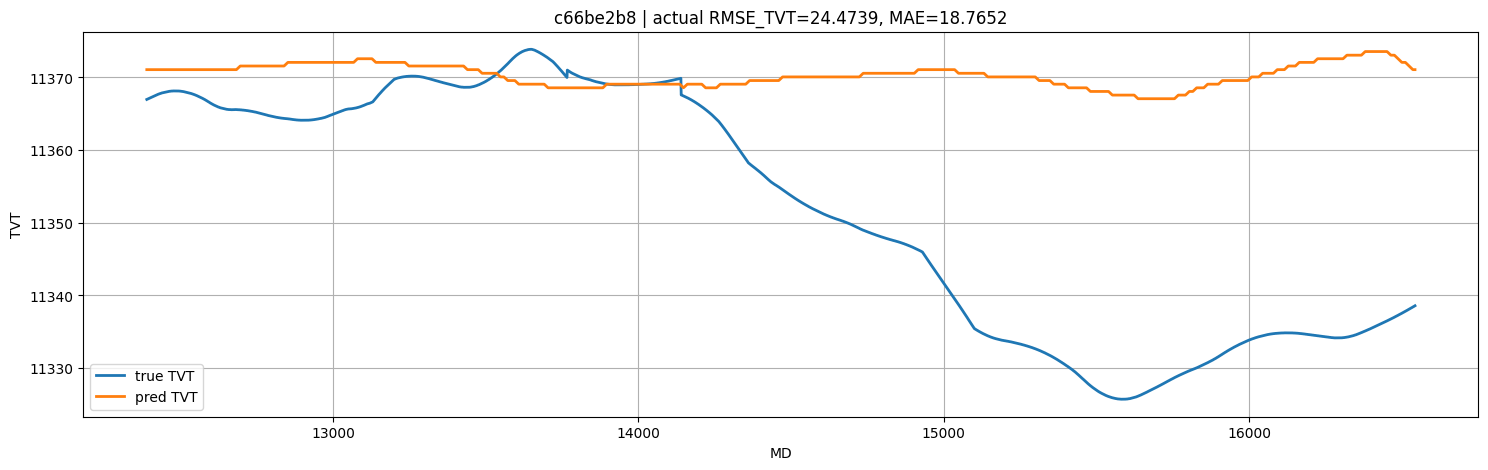

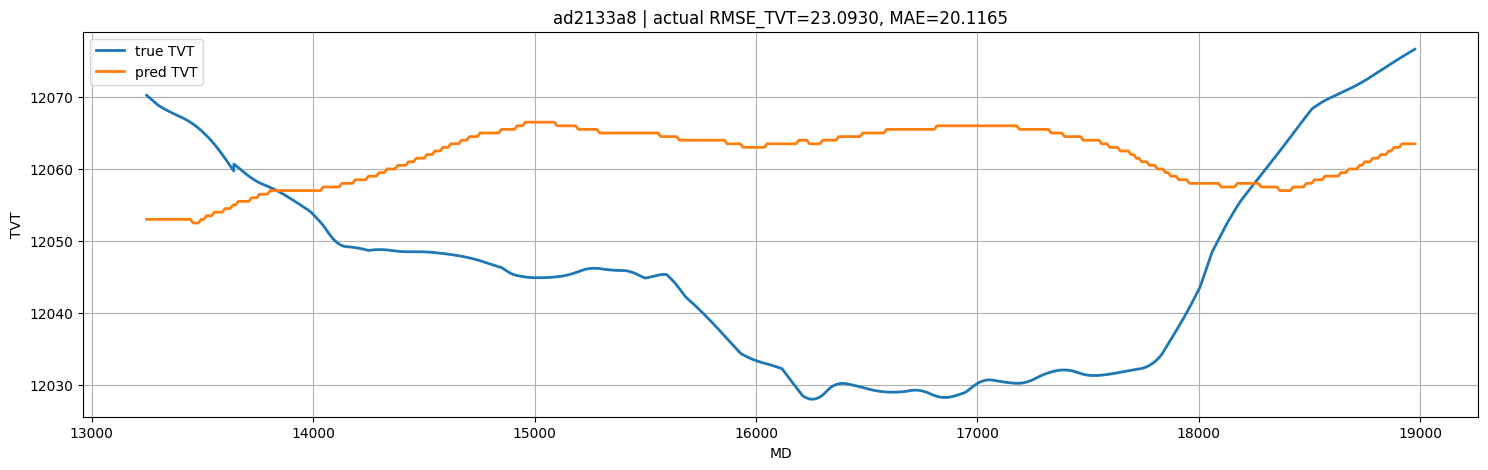

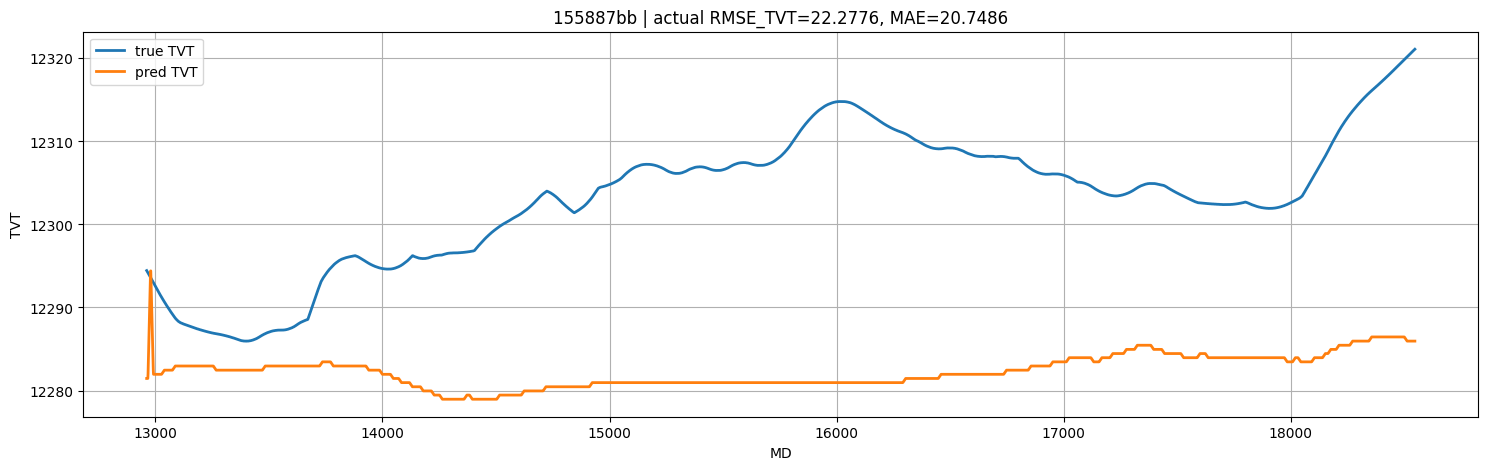

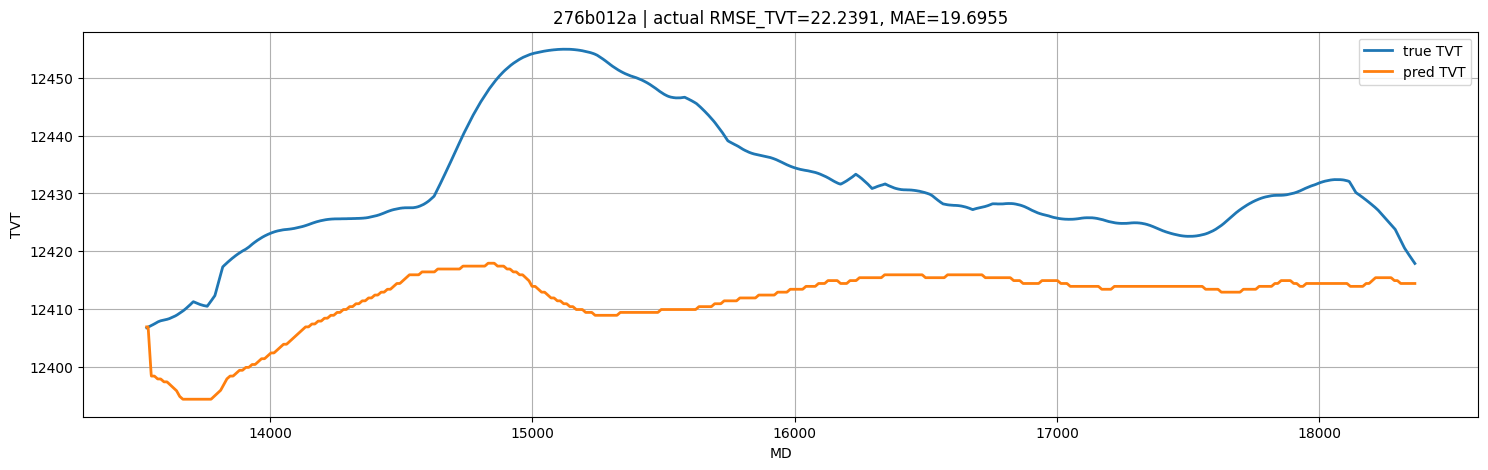

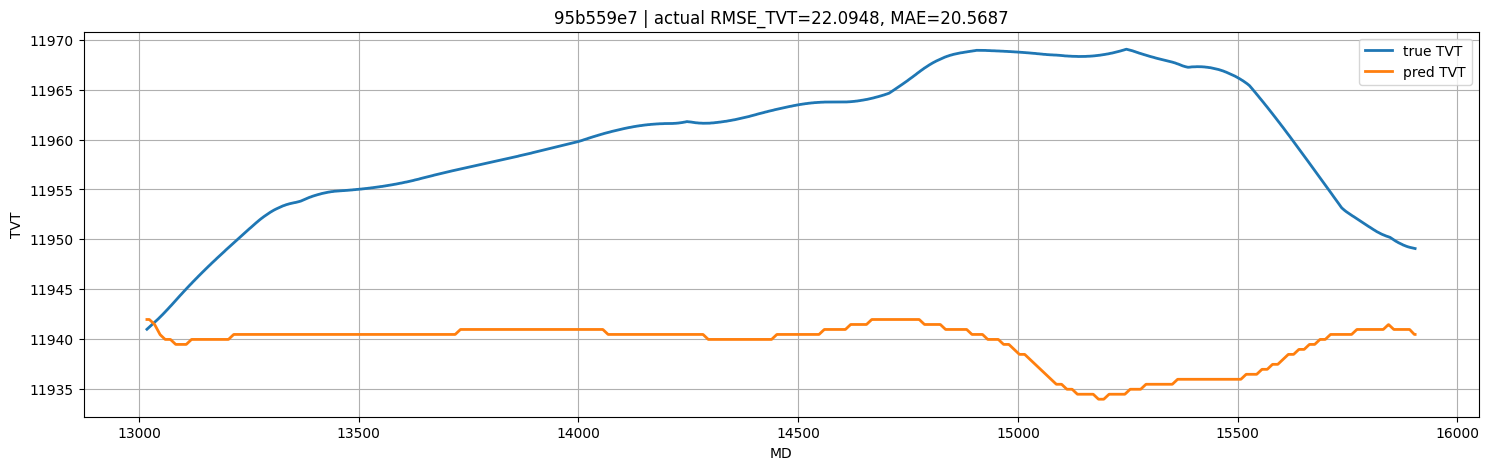

In [27]:
def plot_actual_tvt_prediction(pred_df, sample_id):
    d = pred_df[pred_df["sample_id"] == sample_id].copy()
    if len(d) == 0:
        print("no rows:", sample_id)
        return

    rmse = np.sqrt(np.mean(d["err_tvt"].values ** 2))
    mae = np.mean(np.abs(d["err_tvt"].values))

    fig, ax = plt.subplots(1, 1, figsize=(18, 5))

    ax.plot(d["x"], d["true_tvt"], label="true TVT", linewidth=2)
    ax.plot(d["x"], d["pred_tvt"], label="pred TVT", linewidth=2)

    ax.set_title(f"{sample_id} | actual RMSE_TVT={rmse:.4f}, MAE={mae:.4f}")
    ax.set_xlabel("MD" if "MD" in pd.read_csv(f"{KAGGLE_DIR}/train/{sample_id}__horizontal_well.csv").columns else "row index")
    ax.set_ylabel("TVT")
    ax.legend()
    ax.grid(True)
    plt.show()


# worst 5 wellsを表示
for sid in valid_by_well.head(5)["sample_id"].tolist():
    plot_actual_tvt_prediction(valid_pred_df, sid)